# Bank Customer Churn — End-to-End Analytics & Predictive Modeling
### From Business Diagnostics to Machine Learning-Driven Retention Strategy

**Dataset:** Churn for Bank Customers (10,000 customers, 14 fields)
**Scope:** Business framing → EDA → Segmentation & Cohorting → Retention KPIs → Mitigation Rules → ML Model Development → Risk Scoring → Executive Recommendations


## 01. Business Context

### Business Problem
The bank is losing roughly **1 in 5 customers per year** (20.37% churn rate). Customer acquisition
costs in retail banking are typically 5–7x higher than retention costs, and churn is concentrated
in specific, identifiable segments rather than spread evenly across the portfolio. Without a
systematic way to identify *who* is leaving, *why*, and *how much value* is attached to them, the
bank cannot deploy retention budget efficiently.

### Analytical Objectives
1. Quantify portfolio-level retention health using core KPIs.
2. Segment the customer base demographically (Geography × Gender × Age) to locate concentrated risk.
3. Build product cohorts to test whether product depth (cross-sell) helps or hurts retention.
4. Test behavioral/engagement signals (Activity, Credit Card ownership) as retention levers.
5. Translate findings into concrete, actionable **mitigation rules**.
6. Build a supervised ML model to score every customer's churn probability and prioritize outreach.

### Key Business Questions
- Which geography, gender, and age combinations carry disproportionate churn risk?
- Does holding more products reduce churn, or is there a "tipping point" where it starts to increase it?
- Does being an *active member* meaningfully shield customers from churn — with or without a credit card?
- How much account balance (financial exposure) is walking out the door with churned customers?
- Which customers should Retention/Marketing target first, and with which specific intervention?


## Environment Setup

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13

COLOR_RETAIN = '#2E86AB'
COLOR_CHURN  = '#E63946'
CMAP_RISK    = 'Reds'

RANDOM_STATE = 42
print('Environment ready.')


Environment ready.


## 02. Dataset Overview

In [2]:
df = pd.read_csv(r"C:\Users\USER\Desktop\CAPSTONE PROJECT\Kaggel data\churn.csv")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(10)


Dimensions: 10,000 rows x 14 columns


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0
5,6,15574012,Chu,645,Spain,Male,44,8,"113,755.78",2,1,0,"149,756.71",1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,"10,062.80",0
7,8,15656148,Obinna,376,Germany,Female,29,4,"115,046.74",4,1,0,"119,346.88",1
8,9,15792365,He,501,France,Male,44,4,"142,051.07",2,0,1,"74,940.50",0
9,10,15592389,H?,684,France,Male,27,2,"134,603.88",1,1,1,"71,725.73",0


In [3]:

# --- Schema & Data Types ---
schema = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notnull().sum(),
    'null_count': df.isnull().sum()
})
schema


,dtype,non_null,null_count
RowNumber,int64,10000,0
CustomerId,int64,10000,0
Surname,object,10000,0
CreditScore,int64,10000,0
Geography,object,10000,0
Gender,object,10000,0
Age,int64,10000,0
Tenure,int64,10000,0
Balance,float64,10000,0
NumOfProducts,int64,10000,0


In [4]:

# --- Cardinality ---
cardinality = pd.DataFrame({
    'n_unique': df.nunique(),
    'pct_unique': (df.nunique() / len(df) * 100).round(2)
}).sort_values('n_unique', ascending=False)
cardinality


,n_unique,pct_unique
RowNumber,10000,100.00
CustomerId,10000,100.00
EstimatedSalary,9999,99.99
Balance,6382,63.82
Surname,2932,29.32
CreditScore,460,4.60
Age,70,0.70
Tenure,11,0.11
NumOfProducts,4,0.04
Geography,3,0.03


In [5]:

# --- Descriptive Statistics ---
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.00",NaN,NaN,NaN,"5,000.50","2,886.90",1.00,"2,500.75","5,000.50","7,500.25","10,000.00"
CustomerId,"10,000.00",NaN,NaN,NaN,"15,690,940.57","71,936.19","15,565,701.00","15,628,528.25","15,690,738.00","15,753,233.75","15,815,690.00"
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,"10,000.00",NaN,NaN,NaN,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"10,000.00",NaN,NaN,NaN,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,"10,000.00",NaN,NaN,NaN,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,"10,000.00",NaN,NaN,NaN,"76,485.89","62,397.41",0.00,0.00,"97,198.54","127,644.24","250,898.09"
NumOfProducts,"10,000.00",NaN,NaN,NaN,1.53,0.58,1.00,1.00,1.00,2.00,4.00


## 03. Data Quality & Validation

In [6]:

# --- Missing Values ---
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df = missing_df[missing_df['missing_count'] > 0]
print("Columns with missing values:")
missing_df if len(missing_df) else print("None — dataset is fully populated.")


Columns with missing values:
None — dataset is fully populated.


In [7]:

# --- Duplicate Records ---
dup_rows = df.duplicated().sum()
dup_customer_ids = df['CustomerId'].duplicated().sum()
print(f"Fully duplicated rows: {dup_rows}")
print(f"Duplicate CustomerId values: {dup_customer_ids}")


Fully duplicated rows: 0
Duplicate CustomerId values: 0


In [8]:

# --- Identifier Integrity ---
print(f"CustomerId unique: {df['CustomerId'].is_unique}")
print(f"RowNumber unique & sequential: {(df['RowNumber'] == np.arange(1, len(df)+1)).all()}")
print(f"CustomerId digit-length range: {df['CustomerId'].astype(str).str.len().min()}-{df['CustomerId'].astype(str).str.len().max()}")


CustomerId unique: True
RowNumber unique & sequential: True
CustomerId digit-length range: 8-8


In [9]:

# --- Range Validation ---
range_checks = pd.DataFrame({
    'min': [df.CreditScore.min(), df.Age.min(), df.Tenure.min(), df.Balance.min(), df.NumOfProducts.min(), df.EstimatedSalary.min()],
    'max': [df.CreditScore.max(), df.Age.max(), df.Tenure.max(), df.Balance.max(), df.NumOfProducts.max(), df.EstimatedSalary.max()],
    'expected_range': ['300-850 (FICO-like)', '18-100', '0-10 yrs', '>= 0', '1-4', '>= 0']
}, index=['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary'])
range_checks


,min,max,expected_range
CreditScore,350.00,850.00,300-850 (FICO-like)
Age,18.00,92.00,18-100
Tenure,0.00,10.00,0-10 yrs
Balance,0.00,"250,898.09",>= 0
NumOfProducts,1.00,4.00,1-4
EstimatedSalary,11.58,"199,992.48",>= 0


In [10]:

# --- Logical Validation ---
# Binary flags should only contain {0,1}; Exited should only contain {0,1}
logical_issues = {
    'HasCrCard_invalid': (~df.HasCrCard.isin([0,1])).sum(),
    'IsActiveMember_invalid': (~df.IsActiveMember.isin([0,1])).sum(),
    'Exited_invalid': (~df.Exited.isin([0,1])).sum(),
    'Geography_unexpected': (~df.Geography.isin(['France','Germany','Spain'])).sum(),
    'Gender_unexpected': (~df.Gender.isin(['Male','Female'])).sum(),
    'Age_lt_18': (df.Age < 18).sum(),
    'Balance_negative': (df.Balance < 0).sum(),
    'CreditScore_out_of_300_850': (~df.CreditScore.between(300,850)).sum(),
}
pd.Series(logical_issues, name='violation_count').to_frame()


,violation_count
HasCrCard_invalid,0
IsActiveMember_invalid,0
Exited_invalid,0
Geography_unexpected,0
Gender_unexpected,0
Age_lt_18,0
Balance_negative,0
CreditScore_out_of_300_850,0


In [11]:

# --- Data Quality Summary ---
zero_balance_rate = (df.Balance == 0).mean() * 100
print("DATA QUALITY SUMMARY")
print("="*50)
print(f"Rows                    : {len(df):,}")
print(f"Missing values          : {df.isnull().sum().sum()}")
print(f"Duplicate rows          : {dup_rows}")
print(f"Duplicate CustomerIds   : {dup_customer_ids}")
print(f"Logical violations      : {sum(logical_issues.values())}")
print(f"Zero-balance customers  : {zero_balance_rate:.1f}% (legitimate — likely no-deposit-product holders, not missing data)")
print("VERDICT: Dataset is clean and analysis-ready. No imputation or row removal required.")


DATA QUALITY SUMMARY
Rows                    : 10,000
Missing values          : 0
Duplicate rows          : 0
Duplicate CustomerIds   : 0
Logical violations      : 0
Zero-balance customers  : 36.2% (legitimate — likely no-deposit-product holders, not missing data)
VERDICT: Dataset is clean and analysis-ready. No imputation or row removal required.


## 04. Portfolio Retention KPIs — Core Portfolio Health

In [12]:

total_customers   = len(df)
churned_customers = df.Exited.sum()
retained_customers = total_customers - churned_customers
churn_rate    = churned_customers / total_customers
retention_rate = 1 - churn_rate
active_rate   = df.IsActiveMember.mean()
multi_product_rate = (df.NumOfProducts > 1).mean()
avg_balance   = df.Balance.mean()
churned_balance = df.loc[df.Exited==1, 'Balance'].sum()
total_balance = df.Balance.sum()
balance_exposure = churned_balance / total_balance

kpi_table = pd.DataFrame({
    'Metric': ['Total Customers','Churned Customers','Retained Customers','Churn Rate','Retention Rate',
               'Active Member Rate','Multi-Product Rate','Average Balance','Average Credit Score',
               'Churned Balance','Churned Balance Exposure'],
    'Value': [total_customers, churned_customers, retained_customers, churn_rate, retention_rate,
              active_rate, multi_product_rate, avg_balance, df.CreditScore.mean(),
              churned_balance, balance_exposure]
})
kpi_table


,Metric,Value
0,Total Customers,"10,000.00"
1,Churned Customers,"2,037.00"
2,Retained Customers,"7,963.00"
3,Churn Rate,0.20
4,Retention Rate,0.80
5,Active Member Rate,0.52
6,Multi-Product Rate,0.49
7,Average Balance,"76,485.89"
8,Average Credit Score,650.53
9,Churned Balance,"185,588,094.63"


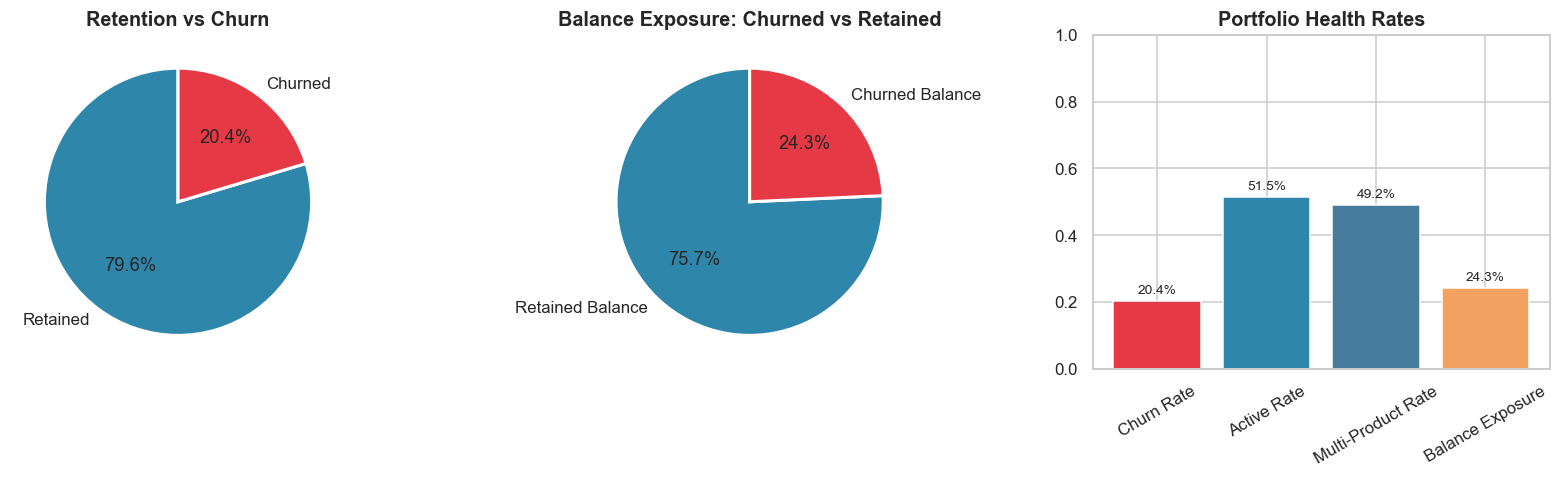

In [13]:

fig, axes = plt.subplots(1, 3, figsize=(15,4.5))

# Retention vs Churn
axes[0].pie([retained_customers, churned_customers], labels=['Retained','Churned'],
            colors=[COLOR_RETAIN, COLOR_CHURN], autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('Retention vs Churn')

# Balance exposure
axes[1].pie([total_balance-churned_balance, churned_balance], labels=['Retained Balance','Churned Balance'],
            colors=[COLOR_RETAIN, COLOR_CHURN], autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Balance Exposure: Churned vs Retained')

# Key rates bar
rates = pd.Series({'Churn Rate':churn_rate,'Active Rate':active_rate,'Multi-Product Rate':multi_product_rate,
                    'Balance Exposure':balance_exposure})
bars = axes[2].bar(rates.index, rates.values, color=['#E63946','#2E86AB','#457B9D','#F4A261'])
axes[2].set_ylim(0,1)
axes[2].set_title('Portfolio Health Rates')
axes[2].tick_params(axis='x', rotation=30)
for b in bars:
    axes[2].text(b.get_x()+b.get_width()/2, b.get_height()+0.02, f'{b.get_height()*100:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()


## 05. Target Distribution

In [14]:

target_dist = df.Exited.value_counts().rename({0:'Retained',1:'Churned'}).to_frame('Customers')
target_dist['Percentage'] = (target_dist['Customers']/len(df)*100).round(2)
target_dist


,Customers,Percentage
Exited,,
Retained,7963,79.63
Churned,2037,20.37


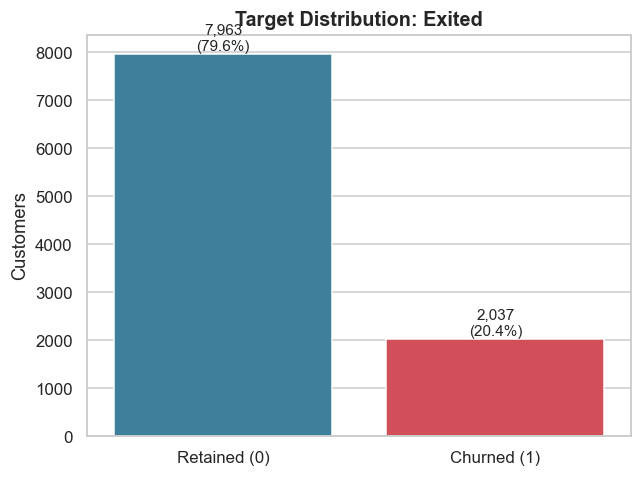

Class Imbalance Implication:
 - Minority class (Churned) = 20.4% of data -> moderate imbalance (~1:3.9).
 - Accuracy alone will be misleading; prioritize Recall, PR-AUC and F1 on the churn class,
   use class_weight='balanced' / scale_pos_weight, and evaluate with stratified splits.


In [15]:

plt.figure(figsize=(6,4.5))
ax = sns.countplot(data=df, x='Exited', hue='Exited', palette=[COLOR_RETAIN, COLOR_CHURN], legend=False)
ax.set_xticks([0,1]); ax.set_xticklabels(['Retained (0)','Churned (1)'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=10)
ax.set_title('Target Distribution: Exited')
ax.set_ylabel('Customers'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

print("Class Imbalance Implication:")
print(f" - Minority class (Churned) = {churn_rate*100:.1f}% of data -> moderate imbalance (~1:3.9).")
print(" - Accuracy alone will be misleading; prioritize Recall, PR-AUC and F1 on the churn class,")
print("   use class_weight='balanced' / scale_pos_weight, and evaluate with stratified splits.")


## 06. Univariate Analysis
Distributions of the core numeric features, each split by churn status to give an early visual read on separation.

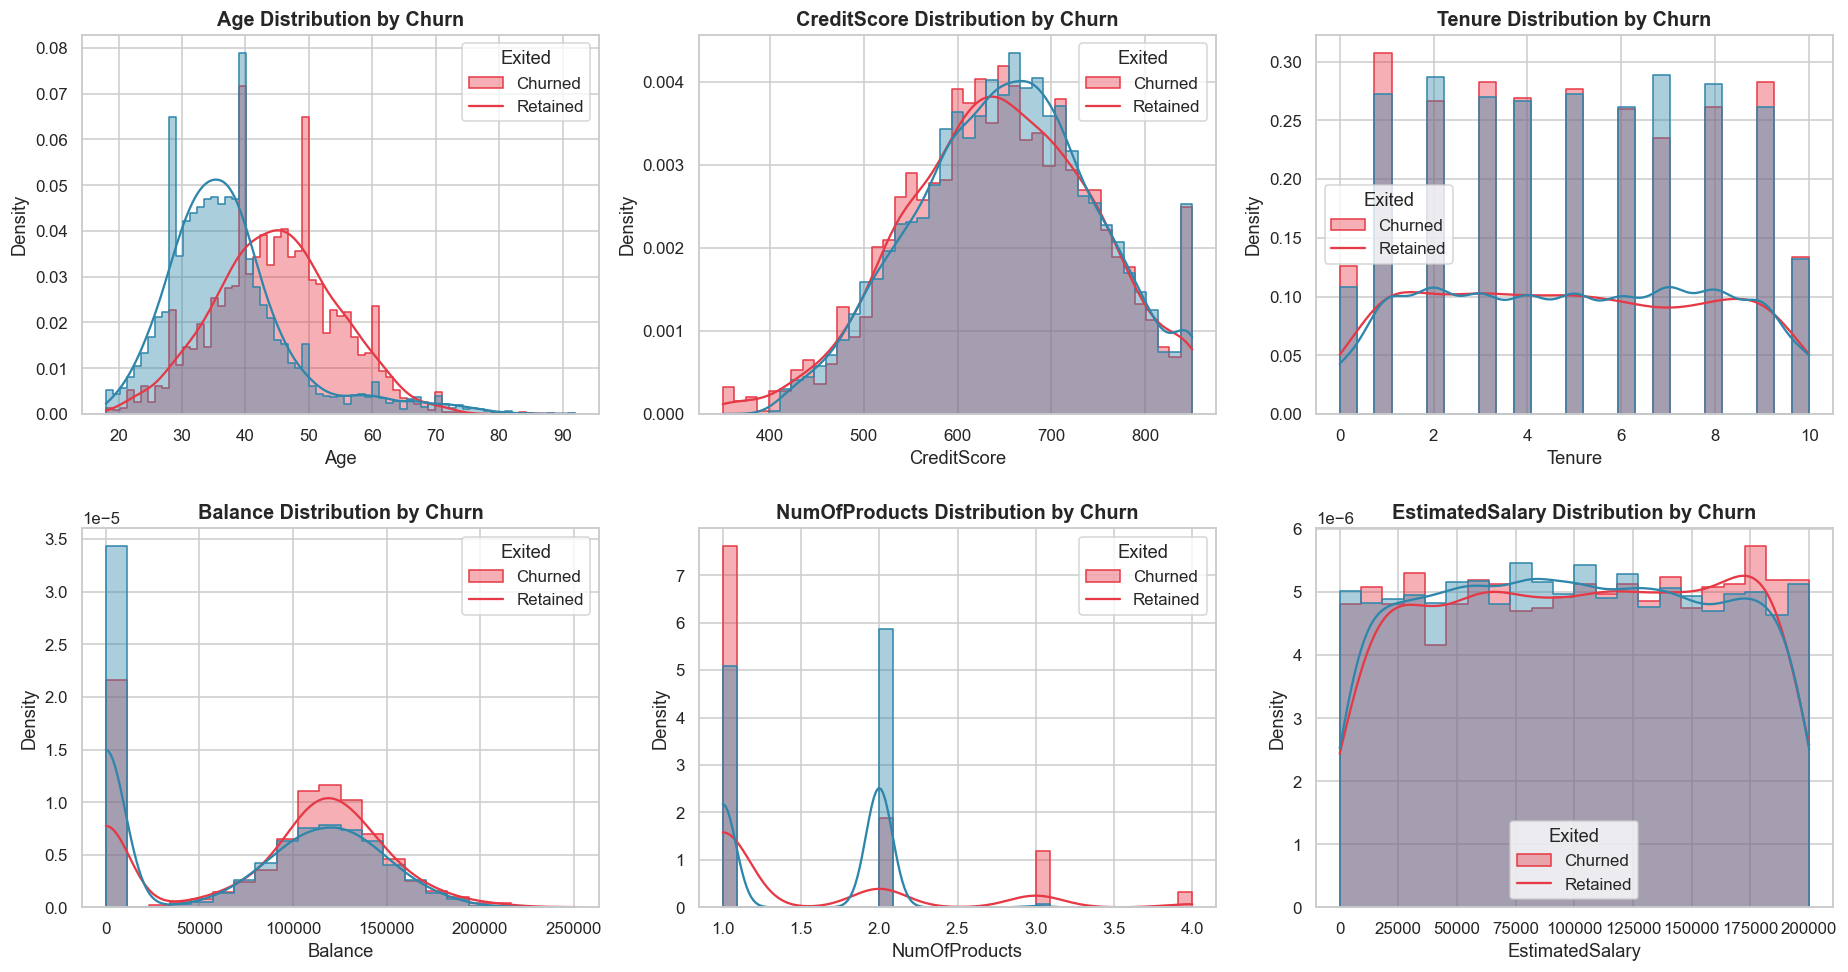

In [16]:

num_features = ['Age','CreditScore','Tenure','Balance','NumOfProducts','EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(17,9))
axes = axes.flatten()
for ax, col in zip(axes, num_features):
    sns.histplot(data=df, x=col, hue='Exited', kde=True, palette=[COLOR_RETAIN, COLOR_CHURN],
                 element='step', stat='density', common_norm=False, ax=ax, alpha=0.4)
    ax.set_title(f'{col} Distribution by Churn')
    ax.legend(title='Exited', labels=['Churned','Retained'])
plt.tight_layout(); plt.show()


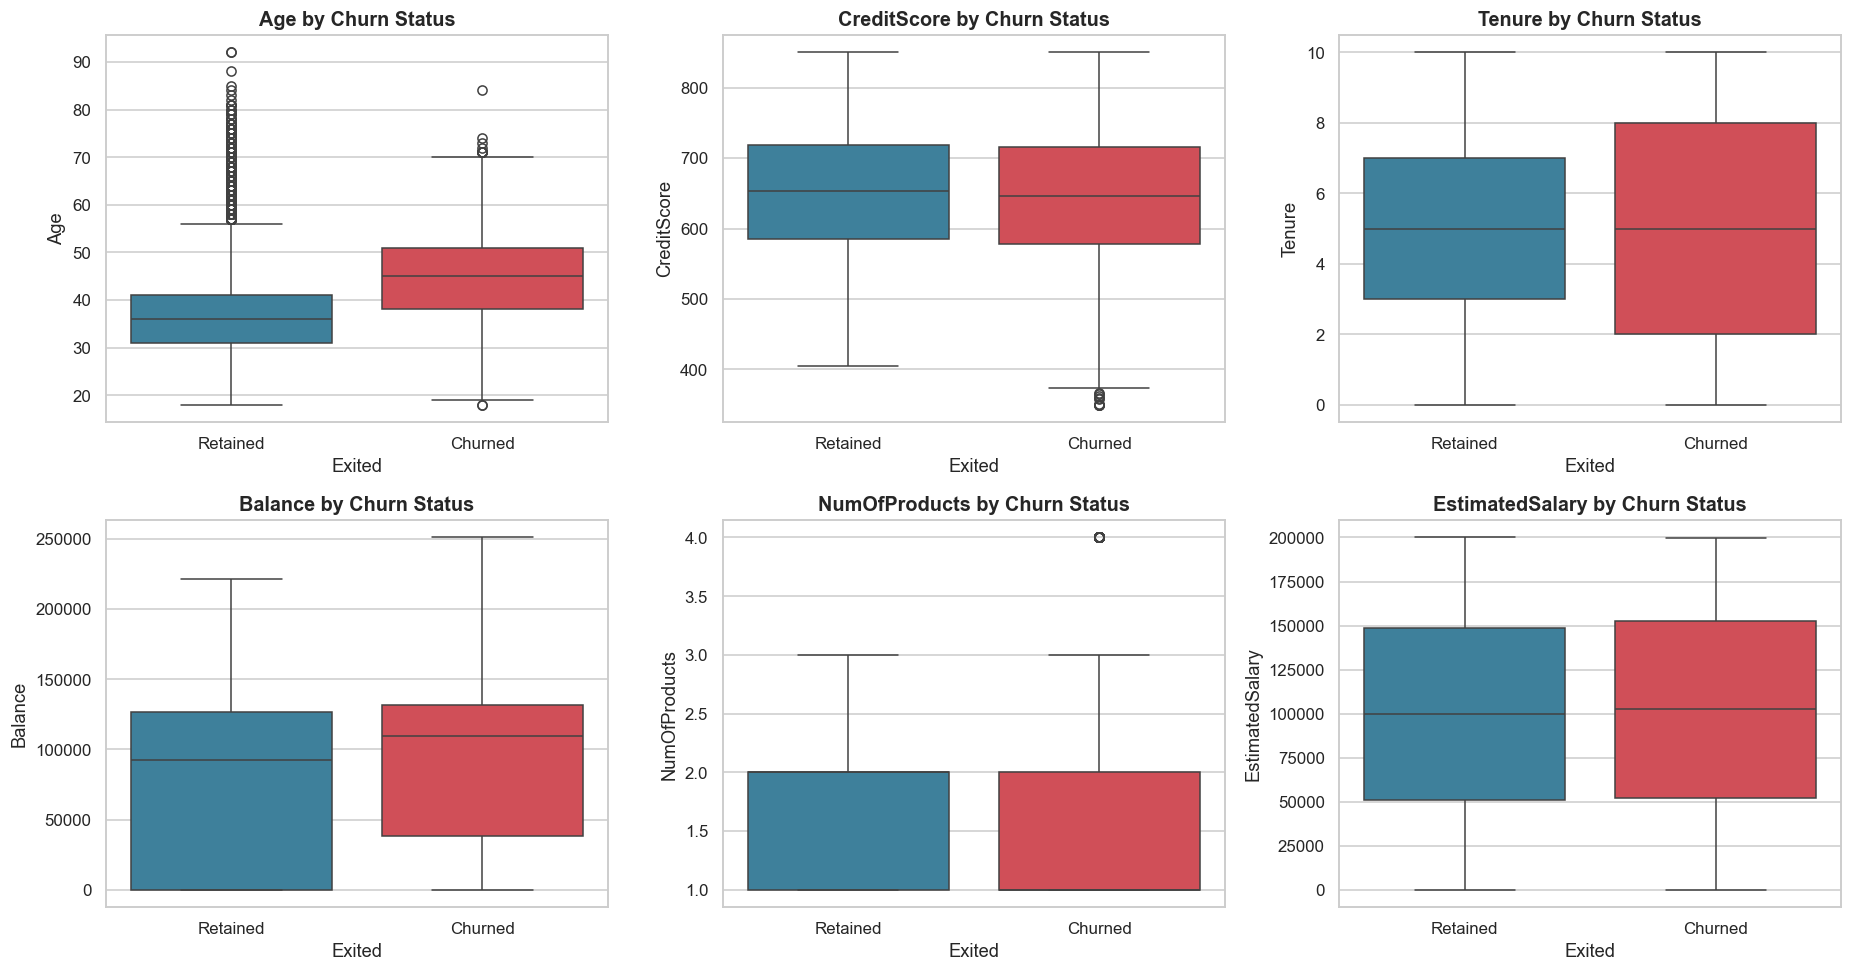

Exited           Retained_mean  Churned_mean
Age                      37.41         44.84
CreditScore             651.85        645.35
Tenure                    5.03          4.93
Balance              72,745.30     91,108.54
NumOfProducts             1.54          1.48
EstimatedSalary      99,738.39    101,465.68


In [17]:

fig, axes = plt.subplots(2, 3, figsize=(17,9))
axes = axes.flatten()
for ax, col in zip(axes, num_features):
    sns.boxplot(data=df, x='Exited', y=col, hue='Exited', palette=[COLOR_RETAIN, COLOR_CHURN], ax=ax, legend=False)
    ax.set_xticks([0,1]); ax.set_xticklabels(['Retained','Churned'])
    ax.set_title(f'{col} by Churn Status')
plt.tight_layout(); plt.show()

print(df[num_features + ['Exited']].groupby('Exited').mean().T.rename(columns={0:'Retained_mean',1:'Churned_mean'}))


## 07. Demographic Segmentation

In [18]:

# --- Age Groups ---
df['AgeGroup'] = pd.cut(df['Age'], bins=[17,25,35,45,55,65,100],
                         labels=['18-25','26-35','36-45','46-55','56-65','66+'])

age_seg = df.groupby('AgeGroup', observed=True).agg(Customers=('Exited','size'), Churned=('Exited','sum'))
age_seg['Churn_Rate_%'] = (age_seg.Churned/age_seg.Customers*100).round(2)
age_seg


,Customers,Churned,Churn_Rate_%
AgeGroup,,,
18-25,611,46,7.53
26-35,3542,301,8.50
36-45,3736,733,19.62
46-55,1311,663,50.57
56-65,536,259,48.32
66+,264,35,13.26


In [19]:

# --- Gender ---
gender_seg = df.groupby('Gender').agg(Customers=('Exited','size'), Churned=('Exited','sum'))
gender_seg['Churn_Rate_%'] = (gender_seg.Churned/gender_seg.Customers*100).round(2)
gender_seg


,Customers,Churned,Churn_Rate_%
Gender,,,
Female,4543,1139,25.07
Male,5457,898,16.46


In [20]:

# --- Geography ---
geo_seg = df.groupby('Geography').agg(Customers=('Exited','size'), Churned=('Exited','sum'),
                                       Total_Balance=('Balance','sum'))
geo_seg['Churn_Rate_%'] = (geo_seg.Churned/geo_seg.Customers*100).round(2)
geo_seg = geo_seg.sort_values('Churn_Rate_%', ascending=False)
geo_seg


,Customers,Churned,Total_Balance,Churn_Rate_%
Geography,,,,
Germany,2509,814,"300,402,861.38",32.44
Spain,2477,413,"153,123,552.01",16.67
France,5014,810,"311,332,479.49",16.15


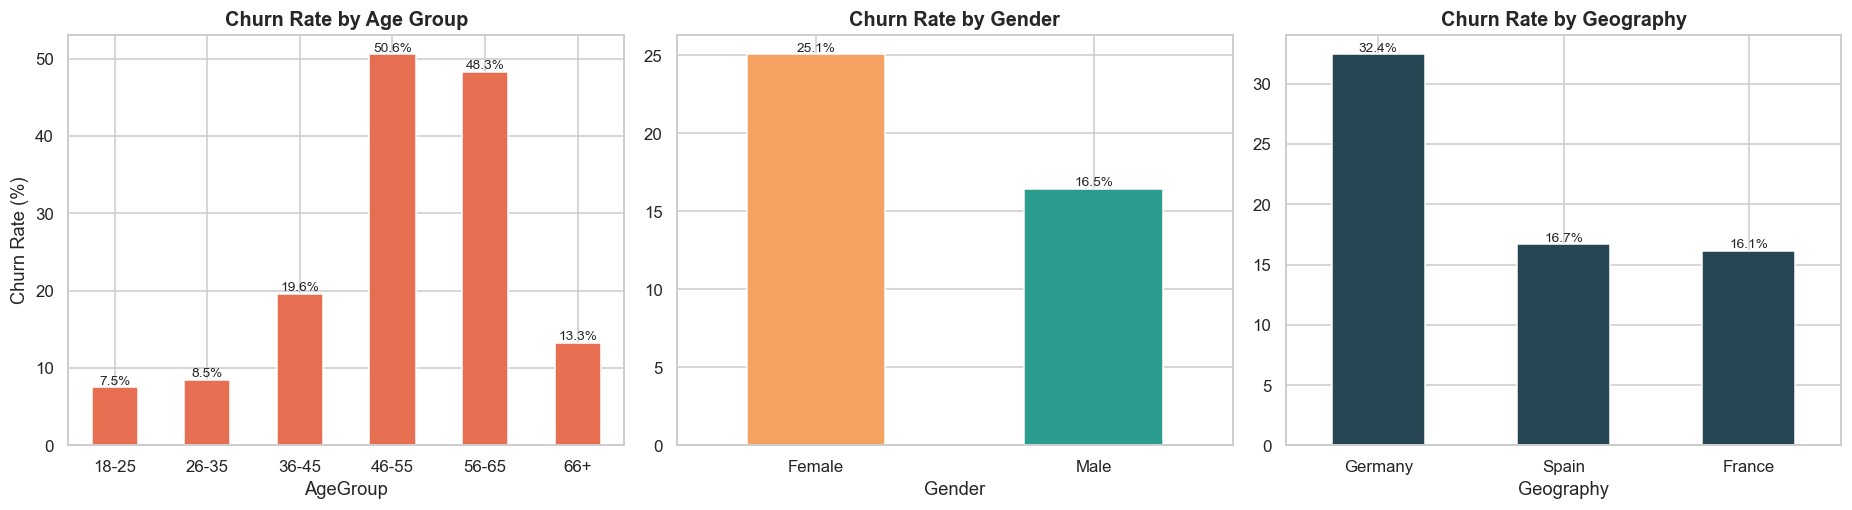

Signal: Germany churns ~2x France/Spain despite having far fewer customers -> concentrated geographic risk.
Signal: Females churn more than males across the portfolio.
Signal: Churn rises sharply through middle age (36-55) then falls for the oldest cohort.


In [21]:

fig, axes = plt.subplots(1, 3, figsize=(17,4.8))

age_seg['Churn_Rate_%'].plot(kind='bar', ax=axes[0], color='#E76F51')
axes[0].set_title('Churn Rate by Age Group'); axes[0].set_ylabel('Churn Rate (%)'); axes[0].tick_params(axis='x', rotation=0)

gender_seg['Churn_Rate_%'].plot(kind='bar', ax=axes[1], color=['#F4A261','#2A9D8F'])
axes[1].set_title('Churn Rate by Gender'); axes[1].tick_params(axis='x', rotation=0)

geo_seg['Churn_Rate_%'].plot(kind='bar', ax=axes[2], color='#264653')
axes[2].set_title('Churn Rate by Geography'); axes[2].tick_params(axis='x', rotation=0)

for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

print("Signal: Germany churns ~2x France/Spain despite having far fewer customers -> concentrated geographic risk.")
print("Signal: Females churn more than males across the portfolio.")
print("Signal: Churn rises sharply through middle age (36-55) then falls for the oldest cohort.")


## 08. Geography × Gender × Age — Multi-Dimensional Demographic Profiles

In [22]:

segment_cols = ['Geography','Gender','AgeGroup']
multi_seg = df.groupby(segment_cols, observed=True).agg(
    Customers=('Exited','size'),
    Churned=('Exited','sum'),
    Total_Balance=('Balance','sum')
).reset_index()
multi_seg['Churn_Rate_%'] = (multi_seg.Churned/multi_seg.Customers*100).round(2)
multi_seg = multi_seg.sort_values('Churn_Rate_%', ascending=False)
print(f"Total multi-dimensional segments generated: {len(multi_seg)}")
multi_seg.head(15)


Total multi-dimensional segments generated: 36


,Geography,Gender,AgeGroup,Customers,Churned,Total_Balance,Churn_Rate_%
15,Germany,Female,46-55,215,148,"25,909,919.42",68.84
16,Germany,Female,56-65,77,52,"9,471,144.18",67.53
21,Germany,Male,46-55,188,122,"22,731,280.26",64.89
22,Germany,Male,56-65,71,44,"8,771,739.09",61.97
4,France,Female,56-65,117,66,"7,871,936.13",56.41
3,France,Female,46-55,281,147,"15,898,654.21",52.31
27,Spain,Female,46-55,156,74,"10,956,975.62",47.44
17,Germany,Female,66+,27,11,"3,169,584.18",40.74
28,Spain,Female,56-65,69,26,"4,714,811.13",37.68
9,France,Male,46-55,316,118,"21,827,832.48",37.34


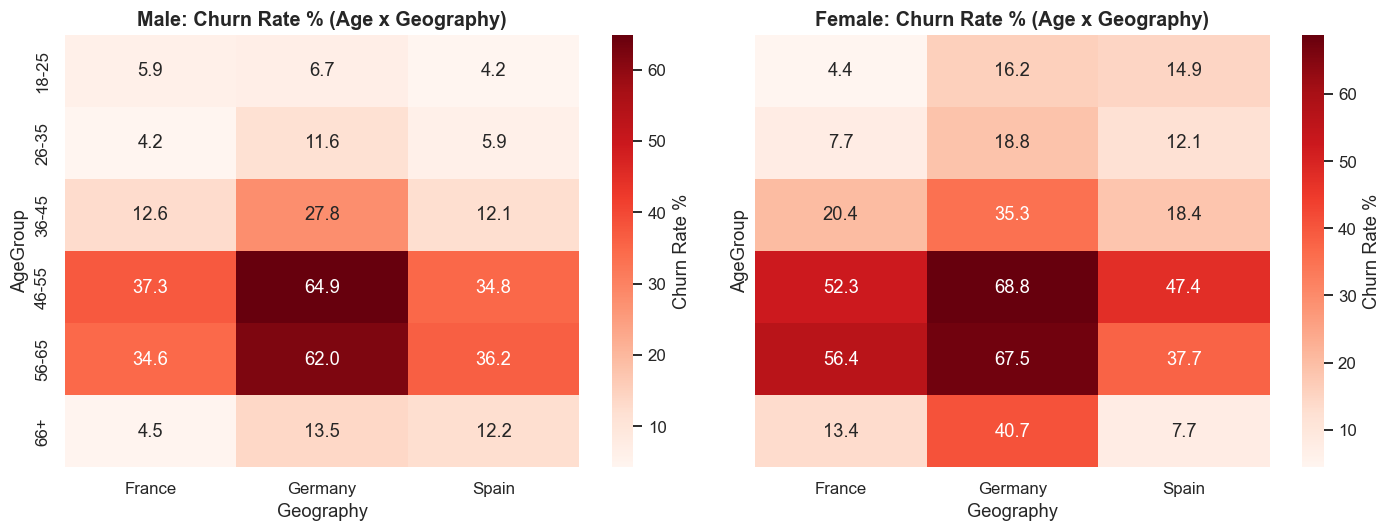

In [23]:

# Heatmap: Geography x AgeGroup churn rate, faceted by Gender
pivot_m = df[df.Gender=='Male'].pivot_table(index='AgeGroup', columns='Geography', values='Exited', aggfunc='mean', observed=True) * 100
pivot_f = df[df.Gender=='Female'].pivot_table(index='AgeGroup', columns='Geography', values='Exited', aggfunc='mean', observed=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13,5), sharey=True)
sns.heatmap(pivot_m, annot=True, fmt='.1f', cmap=CMAP_RISK, ax=axes[0], cbar_kws={'label':'Churn Rate %'})
axes[0].set_title('Male: Churn Rate % (Age x Geography)')
sns.heatmap(pivot_f, annot=True, fmt='.1f', cmap=CMAP_RISK, ax=axes[1], cbar_kws={'label':'Churn Rate %'})
axes[1].set_title('Female: Churn Rate % (Age x Geography)')
plt.tight_layout(); plt.show()


## 09. Top 5 Highest-Risk Segments
A minimum population threshold is applied first so that tiny, statistically noisy segments (e.g. 3 customers, 100% churn)
don't distort the ranking.

In [24]:

MIN_SEGMENT_SIZE = 30  # minimum population threshold for statistical reliability

reliable_segments = multi_seg[multi_seg.Customers >= MIN_SEGMENT_SIZE].copy()
top5_risk = reliable_segments.sort_values('Churn_Rate_%', ascending=False).head(5).reset_index(drop=True)
top5_risk['Segment'] = top5_risk.Geography + ' | ' + top5_risk.Gender + ' | ' + top5_risk.AgeGroup.astype(str)
top5_risk[['Segment','Customers','Churned','Churn_Rate_%','Total_Balance']]


,Segment,Customers,Churned,Churn_Rate_%,Total_Balance
0,Germany | Female | 46-55,215,148,68.84,"25,909,919.42"
1,Germany | Female | 56-65,77,52,67.53,"9,471,144.18"
2,Germany | Male | 46-55,188,122,64.89,"22,731,280.26"
3,Germany | Male | 56-65,71,44,61.97,"8,771,739.09"
4,France | Female | 56-65,117,66,56.41,"7,871,936.13"


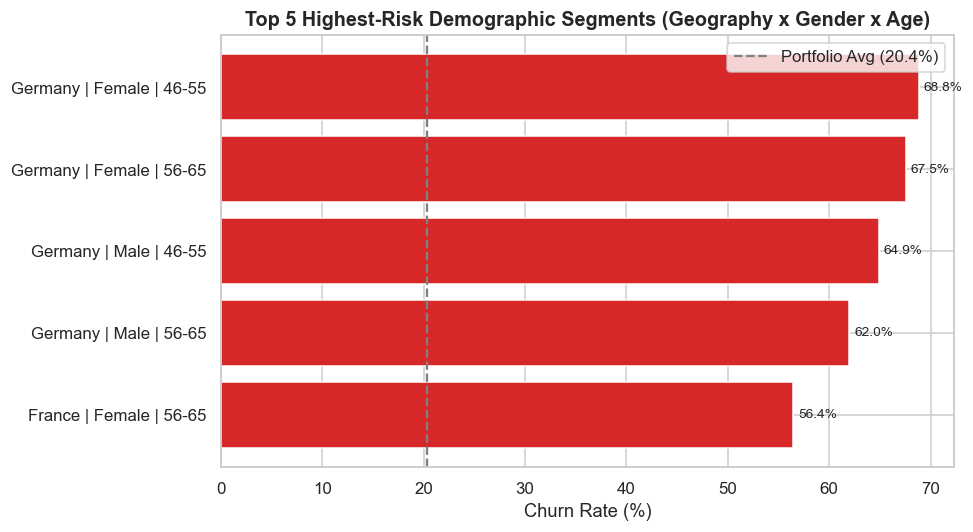

These 5 segments are all Germany-based, skewing female and concentrated in the 46-65 age bracket —
confirming Germany + mid/late-career customers as the portfolio's sharpest demographic risk pocket.


In [25]:

plt.figure(figsize=(9,5))
bars = plt.barh(top5_risk['Segment'][::-1], top5_risk['Churn_Rate_%'][::-1], color='#D62828')
plt.axvline(churn_rate*100, color='gray', linestyle='--', label=f'Portfolio Avg ({churn_rate*100:.1f}%)')
for b in bars:
    plt.text(b.get_width()+0.5, b.get_y()+b.get_height()/2, f'{b.get_width():.1f}%', va='center', fontsize=9)
plt.title('Top 5 Highest-Risk Demographic Segments (Geography x Gender x Age)')
plt.xlabel('Churn Rate (%)'); plt.legend()
plt.tight_layout(); plt.show()

print("These 5 segments are all Germany-based, skewing female and concentrated in the 46-65 age bracket —")
print("confirming Germany + mid/late-career customers as the portfolio's sharpest demographic risk pocket.")


## 10. Financial Risk & Balance Exposure

In [26]:

# --- Balance Bands ---
df['BalanceBand'] = pd.cut(df['Balance'], bins=[-1,0,50000,100000,150000,200000,np.inf],
                            labels=['Zero','1-50K','50-100K','100-150K','150-200K','200K+'])

balance_band_seg = df.groupby('BalanceBand', observed=True).agg(Customers=('Exited','size'), Churned=('Exited','sum'),
                                                                  Total_Balance=('Balance','sum'))
balance_band_seg['Churn_Rate_%'] = (balance_band_seg.Churned/balance_band_seg.Customers*100).round(2)
balance_band_seg


,Customers,Churned,Total_Balance,Churn_Rate_%
BalanceBand,,,,
Zero,3617,500,0.00,13.82
1-50K,75,26,"2,958,564.90",34.67
50-100K,1509,300,"126,555,466.60",19.88
100-150K,3830,987,"473,746,989.74",25.77
150-200K,935,205,"154,450,740.19",21.93
200K+,34,19,"7,147,131.45",55.88


In [27]:

# --- High-Value Customers (top quartile balance) ---
hv_threshold = df.Balance.quantile(0.75)
df['HighValue'] = df.Balance >= hv_threshold
hv_churn = df.groupby('HighValue').Exited.mean() * 100
print(f"High-value threshold (75th pct balance): {hv_threshold:,.0f}")
print(f"Churn rate - High-value customers : {hv_churn[True]:.2f}%")
print(f"Churn rate - Other customers      : {hv_churn[False]:.2f}%")


High-value threshold (75th pct balance): 127,644
Churn rate - High-value customers : 23.68%
Churn rate - Other customers      : 19.27%


In [28]:

# --- Churned Balance & Financial Exposure ---
fin_summary = pd.DataFrame({
    'Total Portfolio Balance': [total_balance],
    'Churned Customers Balance': [churned_balance],
    'Balance Exposure %': [balance_exposure*100],
    'High-Value Churned Balance': [df.loc[(df.Exited==1)&(df.HighValue), 'Balance'].sum()],
})
fin_summary.T.rename(columns={0:'Value'})


,Value
Total Portfolio Balance,"764,858,892.88"
Churned Customers Balance,"185,588,094.63"
Balance Exposure %,24.26
High-Value Churned Balance,"88,654,932.44"


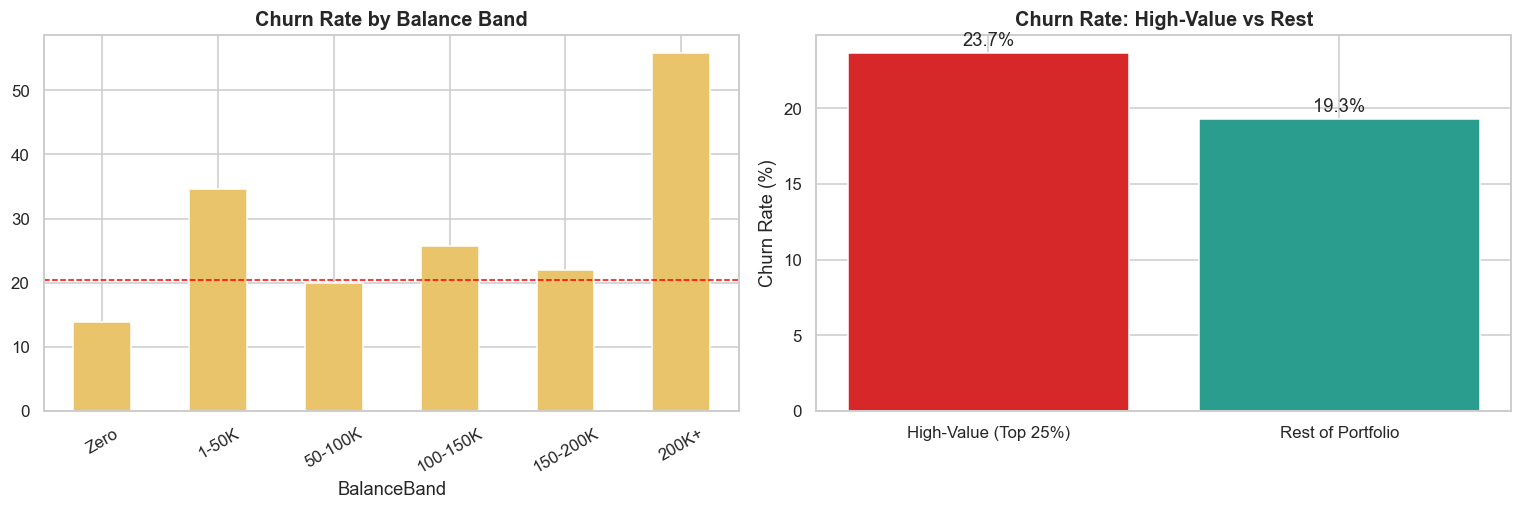

Note: 'Zero' balance band shows a LOWER churn rate here -- this looks counter-intuitive and is
investigated properly in Section 19 (Zero Balance Analysis), where it's cross-cut with product depth.


In [29]:

fig, axes = plt.subplots(1, 2, figsize=(14,4.8))
balance_band_seg['Churn_Rate_%'].plot(kind='bar', ax=axes[0], color='#E9C46A')
axes[0].axhline(churn_rate*100, color='red', linestyle='--', linewidth=1)
axes[0].set_title('Churn Rate by Balance Band'); axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(['High-Value (Top 25%)','Rest of Portfolio'], [hv_churn[True], hv_churn[False]], color=['#D62828','#2A9D8F'])
axes[1].set_title('Churn Rate: High-Value vs Rest'); axes[1].set_ylabel('Churn Rate (%)')
for i,v in enumerate([hv_churn[True], hv_churn[False]]):
    axes[1].text(i, v+0.5, f'{v:.1f}%', ha='center')
plt.tight_layout(); plt.show()

print("Note: 'Zero' balance band shows a LOWER churn rate here -- this looks counter-intuitive and is")
print("investigated properly in Section 19 (Zero Balance Analysis), where it's cross-cut with product depth.")


## 11. Credit Profile Analysis

In [30]:

df['CreditBand'] = pd.cut(df['CreditScore'], bins=[300,579,669,739,799,850],
                           labels=['Poor(<580)','Fair(580-669)','Good(670-739)','Very Good(740-799)','Exceptional(800+)'])

credit_seg = df.groupby('CreditBand', observed=True).agg(Customers=('Exited','size'), Churned=('Exited','sum'))
credit_seg['Churn_Rate_%'] = (credit_seg.Churned/credit_seg.Customers*100).round(2)
credit_seg


,Customers,Churned,Churn_Rate_%
CreditBand,,,
Poor(<580),2362,520,22.02
Fair(580-669),3331,685,20.56
Good(670-739),2428,452,18.62
Very Good(740-799),1224,252,20.59
Exceptional(800+),655,128,19.54


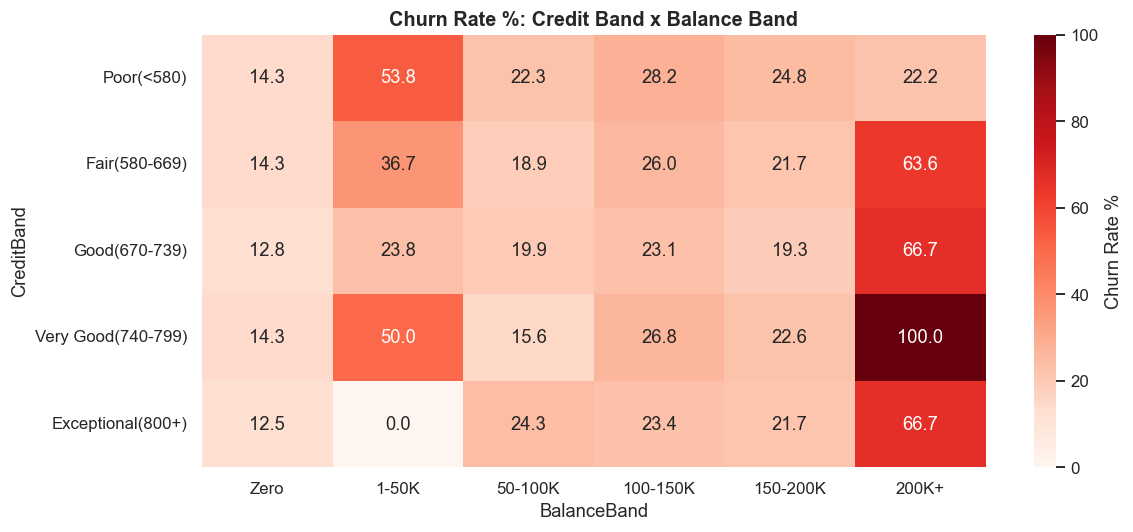

Credit score alone shows only a weak, mostly flat relationship with churn -- it is NOT a strong
standalone driver in this portfolio (unlike Geography, Age, Activity or Product Depth).


In [31]:

# Credit x Balance risk (does low credit + high balance = risk?)
credit_balance_pivot = df.pivot_table(index='CreditBand', columns='BalanceBand', values='Exited', aggfunc='mean', observed=True) * 100

plt.figure(figsize=(11,5))
sns.heatmap(credit_balance_pivot, annot=True, fmt='.1f', cmap=CMAP_RISK, cbar_kws={'label':'Churn Rate %'})
plt.title('Churn Rate %: Credit Band x Balance Band')
plt.tight_layout(); plt.show()

print("Credit score alone shows only a weak, mostly flat relationship with churn -- it is NOT a strong")
print("standalone driver in this portfolio (unlike Geography, Age, Activity or Product Depth).")


## 12. Tenure Analysis — Customer Lifecycle Risk

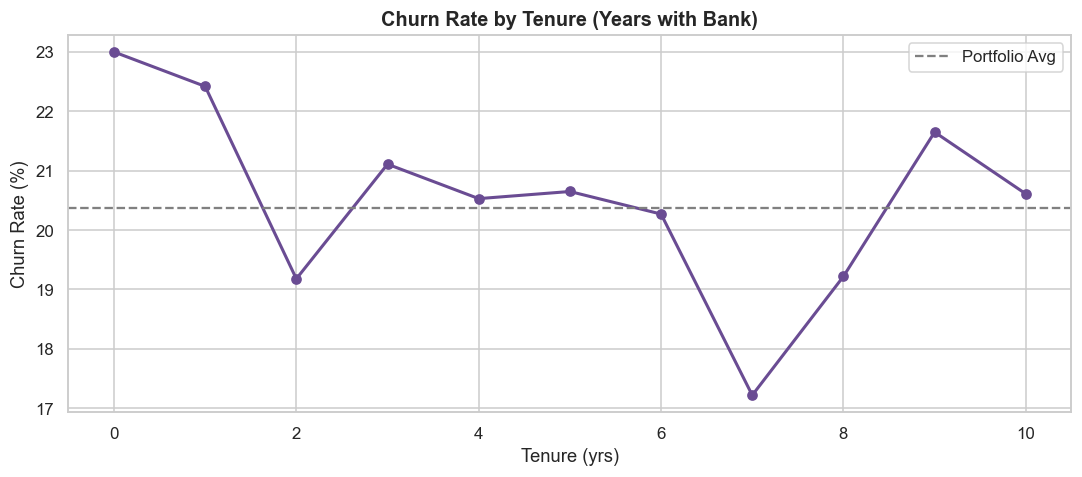

Tenure shows a roughly flat / mildly U-shaped relationship with churn -- new (0yr) and very loyal
(10yr) customers churn at similar rates to the middle of the distribution. Tenure alone is a weak lever.


In [32]:

tenure_seg = df.groupby('Tenure').agg(Customers=('Exited','size'), Churned=('Exited','sum'))
tenure_seg['Churn_Rate_%'] = (tenure_seg.Churned/tenure_seg.Customers*100).round(2)

plt.figure(figsize=(10,4.5))
plt.plot(tenure_seg.index, tenure_seg['Churn_Rate_%'], marker='o', color='#6A4C93', linewidth=2)
plt.axhline(churn_rate*100, color='gray', linestyle='--', label='Portfolio Avg')
plt.title('Churn Rate by Tenure (Years with Bank)')
plt.xlabel('Tenure (yrs)'); plt.ylabel('Churn Rate (%)'); plt.legend()
plt.tight_layout(); plt.show()

print("Tenure shows a roughly flat / mildly U-shaped relationship with churn -- new (0yr) and very loyal")
print("(10yr) customers churn at similar rates to the middle of the distribution. Tenure alone is a weak lever.")


## 13. Product Cohorting — Ecosystem Product Depth

In [33]:

product_seg = df.groupby('NumOfProducts').agg(Customers=('Exited','size'), Churned=('Exited','sum'),
                                                Avg_Balance=('Balance','mean'), Total_Balance=('Balance','sum'))
product_seg['Churn_Rate_%'] = (product_seg.Churned/product_seg.Customers*100).round(2)
product_seg


,Customers,Churned,Avg_Balance,Total_Balance,Churn_Rate_%
NumOfProducts,,,,,
1,5084,1409,"98,551.87","501,037,710.20",27.71
2,4590,348,"51,879.15","238,125,279.28",7.58
3,266,220,"75,458.33","20,071,915.30",82.71
4,60,60,"93,733.13","5,623,988.10",100.00


In [34]:

def product_cohort(n):
    if n == 1: return 'Single-Product'
    if n == 2: return 'Core Cross-Sell (2)'
    return 'Over-Extended (3-4)'

df['ProductCohort'] = df['NumOfProducts'].apply(product_cohort)
cohort_seg = df.groupby('ProductCohort').agg(Customers=('Exited','size'), Churned=('Exited','sum'),
                                              Avg_Balance=('Balance','mean'))
cohort_seg['Churn_Rate_%'] = (cohort_seg.Churned/cohort_seg.Customers*100).round(2)
cohort_seg = cohort_seg.reindex(['Single-Product','Core Cross-Sell (2)','Over-Extended (3-4)'])
cohort_seg


,Customers,Churned,Avg_Balance,Churn_Rate_%
ProductCohort,,,,
Single-Product,5084,1409,"98,551.87",27.71
Core Cross-Sell (2),4590,348,"51,879.15",7.58
Over-Extended (3-4),326,280,"78,821.79",85.89


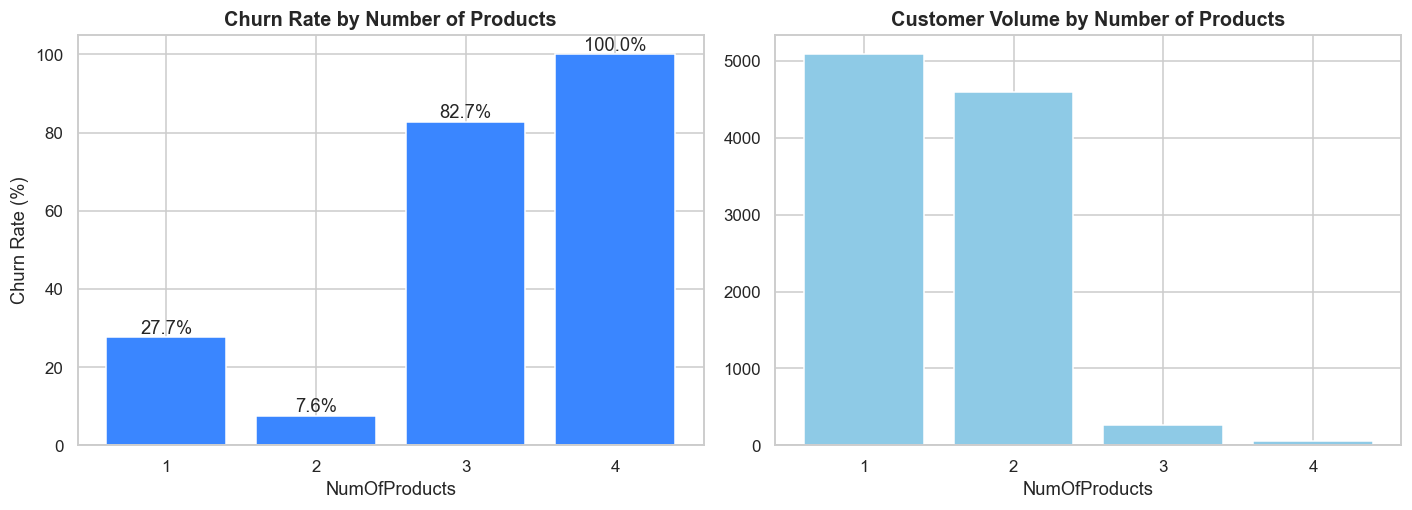

STRIKING PATTERN: Customers with 3 or 4 products churn at extremely high rates (>80%) despite
being a small population. Product depth is NOT protective past 2 products -- it inverts sharply.
This is formalized in Plot A below.


In [35]:

fig, axes = plt.subplots(1, 2, figsize=(13,4.8))
bars = axes[0].bar(product_seg.index.astype(str), product_seg['Churn_Rate_%'], color='#3A86FF')
axes[0].set_title('Churn Rate by Number of Products'); axes[0].set_xlabel('NumOfProducts'); axes[0].set_ylabel('Churn Rate (%)')
for b in bars:
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{b.get_height():.1f}%', ha='center')

axes[1].bar(product_seg.index.astype(str), product_seg['Customers'], color='#8ECAE6')
axes[1].set_title('Customer Volume by Number of Products'); axes[1].set_xlabel('NumOfProducts')
plt.tight_layout(); plt.show()

print("STRIKING PATTERN: Customers with 3 or 4 products churn at extremely high rates (>80%) despite")
print("being a small population. Product depth is NOT protective past 2 products -- it inverts sharply.")
print("This is formalized in Plot A below.")


## 14. Plot A — The Tipping Point of Product Cohorts
Cross-selling from 1 → 2 products is protective. Beyond 2, churn risk inverts violently — this is the "tipping point."
This single relationship is one of the strongest signals in the entire dataset.

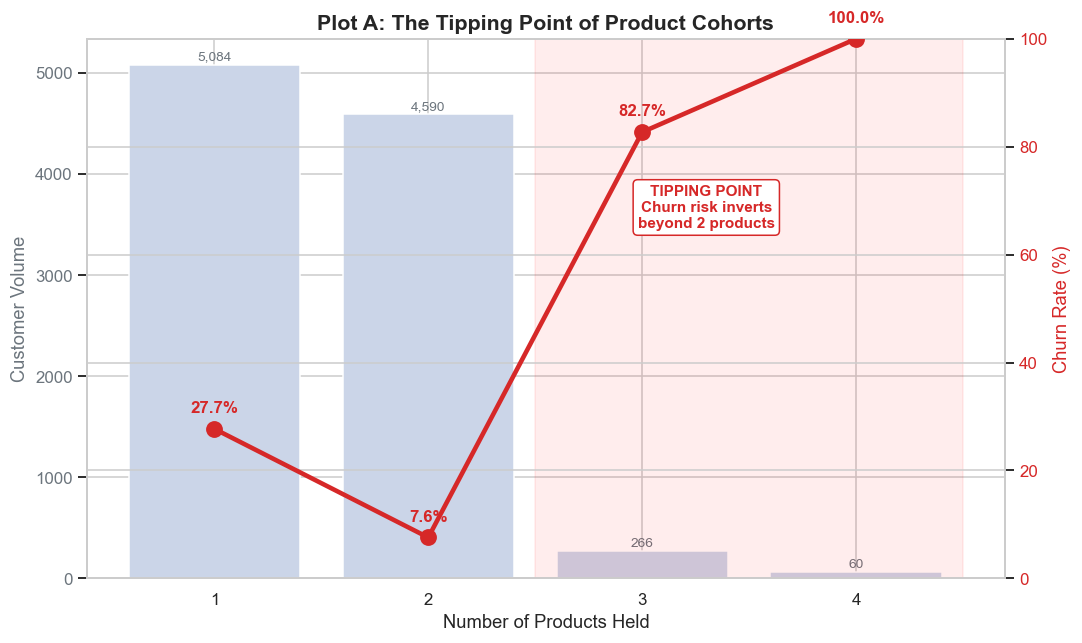

In [36]:

fig, ax1 = plt.subplots(figsize=(10,6))

x = product_seg.index.astype(str)
bars = ax1.bar(x, product_seg['Customers'], color='#CBD5E8', label='Customer Volume', zorder=1)
ax1.set_xlabel('Number of Products Held', fontsize=12)
ax1.set_ylabel('Customer Volume', fontsize=12, color='#6c757d')
ax1.tick_params(axis='y', labelcolor='#6c757d')
for b in bars:
    ax1.text(b.get_x()+b.get_width()/2, b.get_height()+50, f'{int(b.get_height()):,}', ha='center', fontsize=9, color='#6c757d')

ax2 = ax1.twinx()
ax2.plot(x, product_seg['Churn_Rate_%'], color='#D62828', marker='o', markersize=10, linewidth=3, zorder=3, label='Churn Rate %')
ax2.set_ylabel('Churn Rate (%)', fontsize=12, color='#D62828')
ax2.tick_params(axis='y', labelcolor='#D62828')
ax2.set_ylim(0, 100)
for i, v in enumerate(product_seg['Churn_Rate_%']):
    ax2.text(i, v+3, f'{v:.1f}%', ha='center', fontsize=11, fontweight='bold', color='#D62828')

# Highlight the tipping point
ax2.axvspan(1.5, 3.5, color='red', alpha=0.07, zorder=0)
ax2.annotate('TIPPING POINT\nChurn risk inverts\nbeyond 2 products', xy=(2.3, 65), fontsize=10,
             ha='center', color='#D62828', fontweight='bold',
             bbox=dict(boxstyle='round', fc='white', ec='#D62828'))

plt.title('Plot A: The Tipping Point of Product Cohorts', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()


In [37]:

# --- Product x Financial Value ---
product_financial = df.groupby('NumOfProducts').agg(
    Customers=('Exited','size'), Churn_Rate_pct=('Exited', lambda x: round(x.mean()*100,2)),
    Avg_Balance=('Balance','mean'), Total_Balance_Exposure=('Balance', lambda x: x[df.loc[x.index,'Exited']==1].sum())
)
product_financial


,Customers,Churn_Rate_pct,Avg_Balance,Total_Balance_Exposure
NumOfProducts,,,,
1,5084,27.71,"98,551.87","129,668,607.08"
2,4590,7.58,"51,879.15","31,407,820.29"
3,266,82.71,"75,458.33","18,887,679.16"
4,60,100.00,"93,733.13","5,623,988.10"


## 15. Activity Analysis — Active vs Inactive

In [38]:

activity_seg = df.groupby('IsActiveMember').agg(Customers=('Exited','size'), Churned=('Exited','sum'))
activity_seg['Churn_Rate_%'] = (activity_seg.Churned/activity_seg.Customers*100).round(2)
activity_seg.index = activity_seg.index.map({0:'Inactive', 1:'Active'})
activity_seg


,Customers,Churned,Churn_Rate_%
IsActiveMember,,,
Inactive,4849,1302,26.85
Active,5151,735,14.27


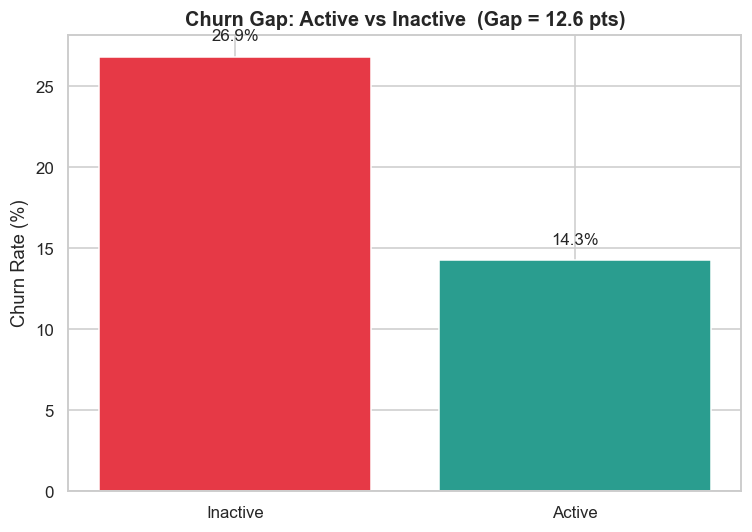

Engagement Profile: Inactive members churn at 26.9% vs
14.3% for active members -- a 12.6-point gap.
Digital/behavioral engagement (IsActiveMember) is one of the single strongest churn predictors available.


In [39]:

churn_gap = activity_seg.loc['Inactive','Churn_Rate_%'] - activity_seg.loc['Active','Churn_Rate_%']

plt.figure(figsize=(7,5))
bars = plt.bar(activity_seg.index, activity_seg['Churn_Rate_%'], color=['#E63946','#2A9D8F'])
for b in bars:
    plt.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{b.get_height():.1f}%', ha='center', fontsize=11)
plt.title(f'Churn Gap: Active vs Inactive  (Gap = {churn_gap:.1f} pts)')
plt.ylabel('Churn Rate (%)')
plt.tight_layout(); plt.show()

print(f"Engagement Profile: Inactive members churn at {activity_seg.loc['Inactive','Churn_Rate_%']:.1f}% vs")
print(f"{activity_seg.loc['Active','Churn_Rate_%']:.1f}% for active members -- a {churn_gap:.1f}-point gap.")
print("Digital/behavioral engagement (IsActiveMember) is one of the single strongest churn predictors available.")


## 16. Credit Card × Activity — Cross-Tab & Interaction Analysis

In [40]:

# --- Cross-tab: counts ---
crosstab_counts = pd.crosstab(df.HasCrCard, df.IsActiveMember,
                               rownames=['HasCrCard'], colnames=['IsActiveMember'])
crosstab_counts.index = crosstab_counts.index.map({0:'No Card',1:'Has Card'})
crosstab_counts.columns = crosstab_counts.columns.map({0:'Inactive',1:'Active'})
print("Customer counts:")
crosstab_counts


Customer counts:


IsActiveMember,Inactive,Active
HasCrCard,,
No Card,1401,1544
Has Card,3448,3607


In [41]:

# --- Cross-tab: churn rate ---
crosstab_churn = df.pivot_table(index='HasCrCard', columns='IsActiveMember', values='Exited', aggfunc='mean') * 100
crosstab_churn.index = crosstab_churn.index.map({0:'No Card',1:'Has Card'})
crosstab_churn.columns = crosstab_churn.columns.map({0:'Inactive',1:'Active'})
print("Churn Rate % by Card x Activity interaction:")
crosstab_churn.round(2)


Churn Rate % by Card x Activity interaction:


IsActiveMember,Inactive,Active
HasCrCard,,
No Card,25.70,16.39
Has Card,27.32,13.36


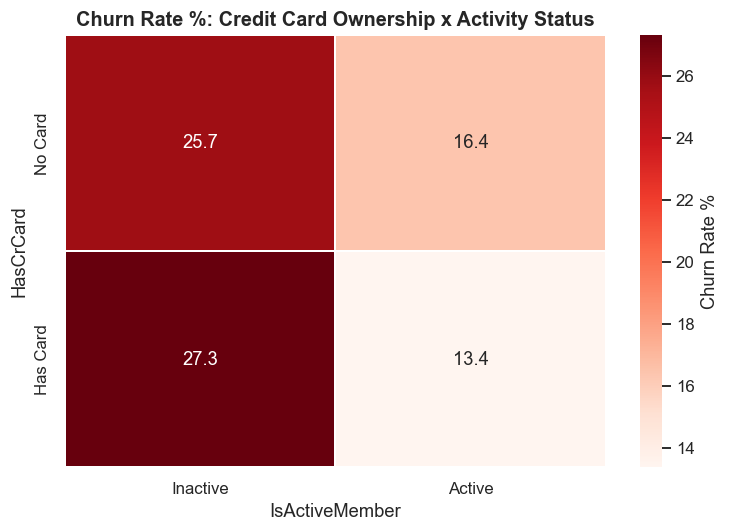

Interaction check: does having a credit card change the churn gap between active/inactive members?
Active/Inactive churn gap, No Card : 9.3 pts
Active/Inactive churn gap, Has Card: 14.0 pts
-> Activity is the dominant driver; card ownership alone barely moves churn without activity behind it.


In [42]:

plt.figure(figsize=(7,5))
sns.heatmap(crosstab_churn, annot=True, fmt='.1f', cmap=CMAP_RISK, cbar_kws={'label':'Churn Rate %'}, linewidths=1)
plt.title('Churn Rate %: Credit Card Ownership x Activity Status')
plt.tight_layout(); plt.show()

print("Interaction check: does having a credit card change the churn gap between active/inactive members?")
gap_no_card = crosstab_churn.loc['No Card','Inactive'] - crosstab_churn.loc['No Card','Active']
gap_has_card = crosstab_churn.loc['Has Card','Inactive'] - crosstab_churn.loc['Has Card','Active']
print(f"Active/Inactive churn gap, No Card : {gap_no_card:.1f} pts")
print(f"Active/Inactive churn gap, Has Card: {gap_has_card:.1f} pts")
print("-> Activity is the dominant driver; card ownership alone barely moves churn without activity behind it.")


## 17. Plot B — The Digital Membership Shield
Combining Activity Status and Credit Card ownership into a single 4-quadrant behavioral view shows that
**activity, not card ownership, is the real shield** — and the two combined define the most and least protected cohorts.

In [43]:

df['BehavioralCohort'] = np.select(
    [
        (df.IsActiveMember==1) & (df.HasCrCard==1),
        (df.IsActiveMember==1) & (df.HasCrCard==0),
        (df.IsActiveMember==0) & (df.HasCrCard==1),
        (df.IsActiveMember==0) & (df.HasCrCard==0),
    ],
    ['Active + Card (Shielded)','Active + No Card','Inactive + Card','Inactive + No Card (Exposed)'],
    default='Unknown'
)

shield_seg = df.groupby('BehavioralCohort').agg(Customers=('Exited','size'), Churned=('Exited','sum'))
shield_seg['Churn_Rate_%'] = (shield_seg.Churned/shield_seg.Customers*100).round(2)
shield_order = ['Active + Card (Shielded)','Active + No Card','Inactive + Card','Inactive + No Card (Exposed)']
shield_seg = shield_seg.reindex(shield_order)
shield_seg


,Customers,Churned,Churn_Rate_%
BehavioralCohort,,,
Active + Card (Shielded),3607,482,13.36
Active + No Card,1544,253,16.39
Inactive + Card,3448,942,27.32
Inactive + No Card (Exposed),1401,360,25.70


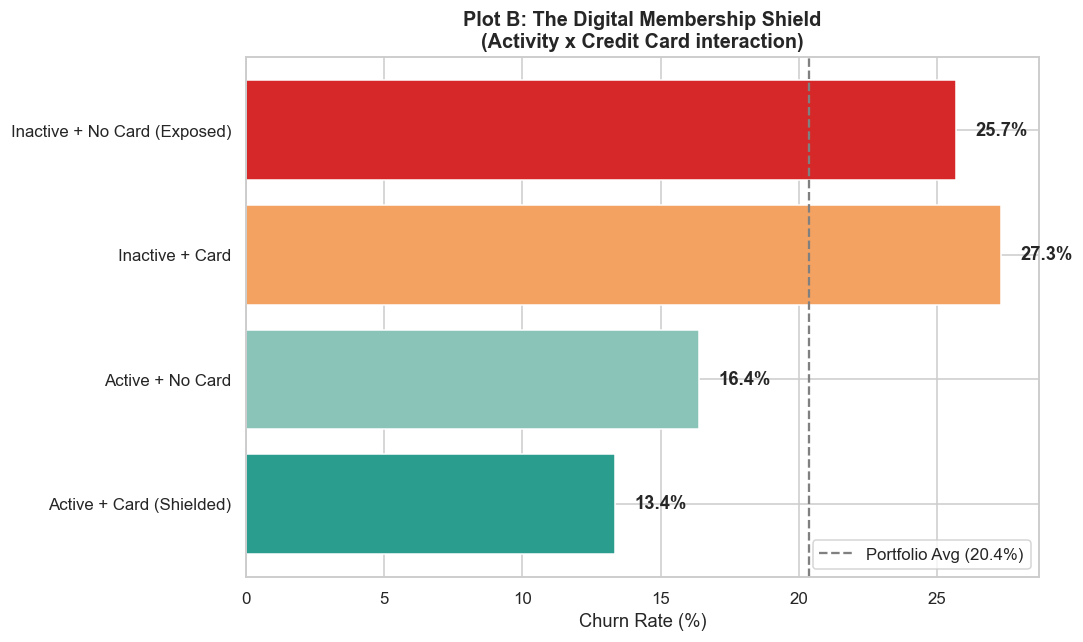

'Digital Membership Shield gap' (Exposed - Shielded) = 12.3 percentage points.
This is the widest, cleanest behavioral gap in the dataset -- engagement, layered with card ownership,
is the strongest actionable (i.e. influenceable) retention lever the bank has.


In [44]:

fig, ax = plt.subplots(figsize=(10,6))
colors = ['#2A9D8F','#8AC4B8','#F4A261','#D62828']
bars = ax.barh(shield_seg.index, shield_seg['Churn_Rate_%'], color=colors)
ax.axvline(churn_rate*100, color='gray', linestyle='--', label=f'Portfolio Avg ({churn_rate*100:.1f}%)')
for b in bars:
    ax.text(b.get_width()+0.7, b.get_y()+b.get_height()/2, f'{b.get_width():.1f}%', va='center', fontweight='bold')
ax.set_xlabel('Churn Rate (%)')
ax.set_title('Plot B: The Digital Membership Shield\n(Activity x Credit Card interaction)', fontsize=13)
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

gap = shield_seg.loc['Inactive + No Card (Exposed)','Churn_Rate_%'] - shield_seg.loc['Active + Card (Shielded)','Churn_Rate_%']
print(f"'Digital Membership Shield gap' (Exposed - Shielded) = {gap:.1f} percentage points.")
print("This is the widest, cleanest behavioral gap in the dataset -- engagement, layered with card ownership,")
print("is the strongest actionable (i.e. influenceable) retention lever the bank has.")


## 18. Product × Activity Cohorts — The Digital Activity Gap

In [45]:

prod_activity_pivot_churn = df.pivot_table(index='ProductCohort', columns='IsActiveMember', values='Exited', aggfunc='mean') * 100
prod_activity_pivot_churn.columns = ['Inactive','Active']
prod_activity_pivot_churn = prod_activity_pivot_churn.reindex(['Single-Product','Core Cross-Sell (2)','Over-Extended (3-4)'])
prod_activity_pivot_churn['Digital_Activity_Gap_pts'] = (prod_activity_pivot_churn['Inactive'] - prod_activity_pivot_churn['Active']).round(2)
prod_activity_pivot_churn.round(2)


,Inactive,Active,Digital_Activity_Gap_pts
ProductCohort,,,
Single-Product,36.65,18.92,17.73
Core Cross-Sell (2),9.89,5.56,4.33
Over-Extended (3-4),90.22,80.28,9.94


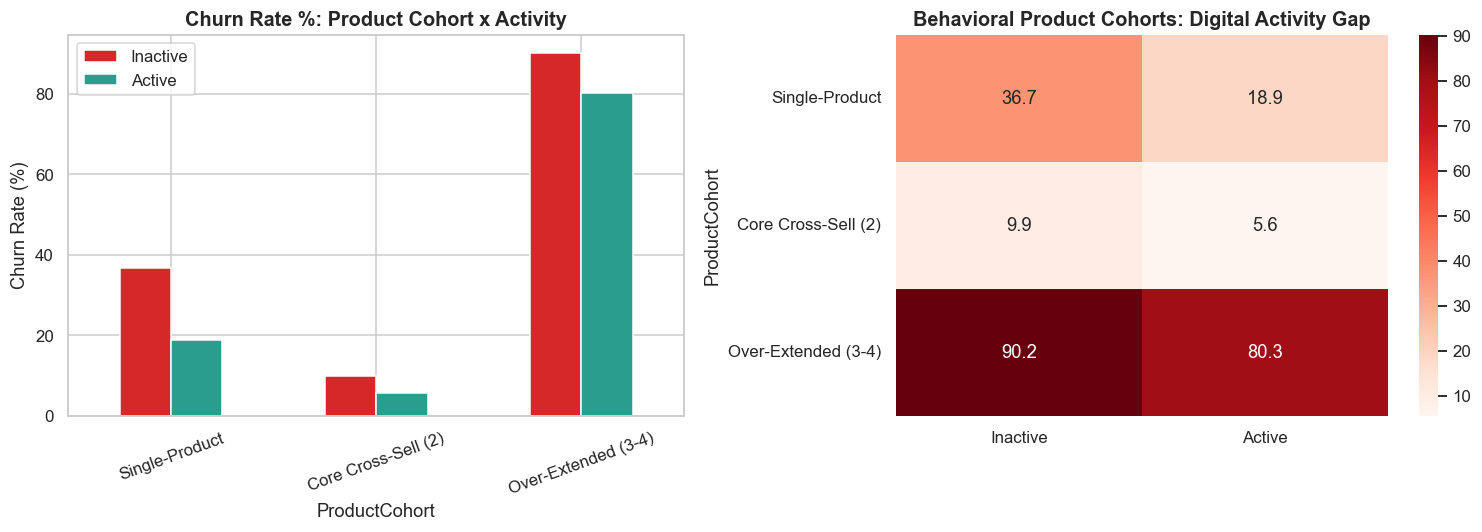

The Over-Extended (3-4 product) cohort churns catastrophically regardless of activity status --
this points to product-fit / cross-sell mis-selling rather than an engagement problem for that group.
For Single-Product and Core Cross-Sell cohorts, activity closes much of the churn gap -- classic
engagement-driven risk that mitigation campaigns can realistically move.


In [46]:

prod_activity_count = df.pivot_table(index='ProductCohort', columns='IsActiveMember', values='Exited', aggfunc='size')
prod_activity_count.columns = ['Inactive','Active']
prod_activity_count = prod_activity_count.reindex(['Single-Product','Core Cross-Sell (2)','Over-Extended (3-4)'])

fig, axes = plt.subplots(1, 2, figsize=(14,5))
prod_activity_pivot_churn[['Inactive','Active']].plot(kind='bar', ax=axes[0], color=['#D62828','#2A9D8F'])
axes[0].set_title('Churn Rate %: Product Cohort x Activity'); axes[0].set_ylabel('Churn Rate (%)'); axes[0].tick_params(axis='x', rotation=20)

sns.heatmap(prod_activity_pivot_churn[['Inactive','Active']], annot=True, fmt='.1f', cmap=CMAP_RISK, ax=axes[1])
axes[1].set_title('Behavioral Product Cohorts: Digital Activity Gap')
plt.tight_layout(); plt.show()

print("The Over-Extended (3-4 product) cohort churns catastrophically regardless of activity status --")
print("this points to product-fit / cross-sell mis-selling rather than an engagement problem for that group.")
print("For Single-Product and Core Cross-Sell cohorts, activity closes much of the churn gap -- classic")
print("engagement-driven risk that mitigation campaigns can realistically move.")


## 19. Zero Balance Analysis

In [47]:

zero_balance_rate = (df.Balance==0).mean()*100
zb_churn = df.groupby(df.Balance==0).Exited.mean()*100
zb_churn.index = zb_churn.index.map({True:'Zero Balance', False:'Non-Zero Balance'})

print(f"Zero-balance rate: {zero_balance_rate:.1f}% of portfolio")
print(zb_churn.round(2))


Zero-balance rate: 36.2% of portfolio
Balance
Non-Zero Balance   24.08
Zero Balance       13.82
Name: Exited, dtype: float64


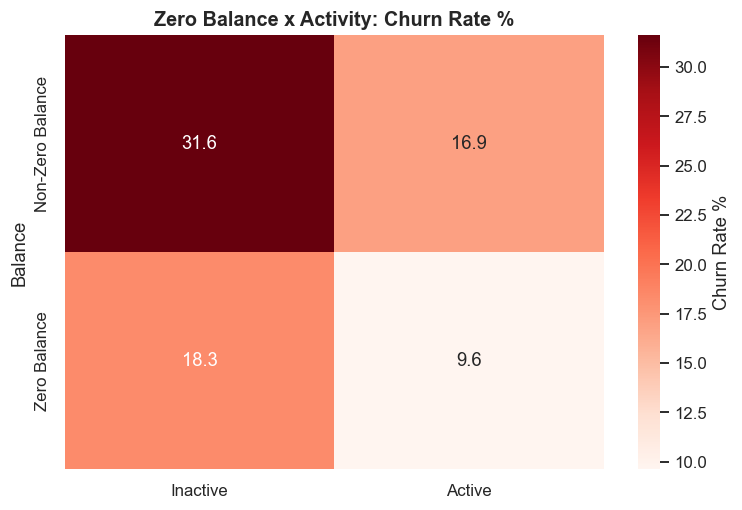

Zero-balance customers are NOT inherently high-risk in isolation (many are simply loan-only /
no-deposit-product customers). Risk only escalates for zero-balance customers who are also inactive --
another confirmation that engagement, not balance alone, is the dominant behavioral signal.


In [48]:

zb_activity = df.pivot_table(index=df.Balance==0, columns='IsActiveMember', values='Exited', aggfunc='mean')*100
zb_activity.index = zb_activity.index.map({True:'Zero Balance', False:'Non-Zero Balance'})
zb_activity.columns = ['Inactive','Active']

plt.figure(figsize=(7,4.8))
sns.heatmap(zb_activity, annot=True, fmt='.1f', cmap=CMAP_RISK, cbar_kws={'label':'Churn Rate %'})
plt.title('Zero Balance x Activity: Churn Rate %')
plt.tight_layout(); plt.show()

print("Zero-balance customers are NOT inherently high-risk in isolation (many are simply loan-only /")
print("no-deposit-product customers). Risk only escalates for zero-balance customers who are also inactive --")
print("another confirmation that engagement, not balance alone, is the dominant behavioral signal.")


## 20. Behavioural Risk Isolation

In [49]:

# Combine the three strongest behavioral/structural flags into a risk score
df['RiskFlags'] = (
    (df.IsActiveMember==0).astype(int) +
    (df.NumOfProducts>=3).astype(int) +
    (df.AgeGroup.isin(['46-55','56-65'])).astype(int) +
    (df.Geography=='Germany').astype(int)
)

risk_flag_seg = df.groupby('RiskFlags').agg(Customers=('Exited','size'), Churned=('Exited','sum'))
risk_flag_seg['Churn_Rate_%'] = (risk_flag_seg.Churned/risk_flag_seg.Customers*100).round(2)
risk_flag_seg


,Customers,Churned,Churn_Rate_%
RiskFlags,,,
0,3103,201,6.48
1,4682,715,15.27
2,1823,787,43.17
3,365,307,84.11
4,27,27,100.00


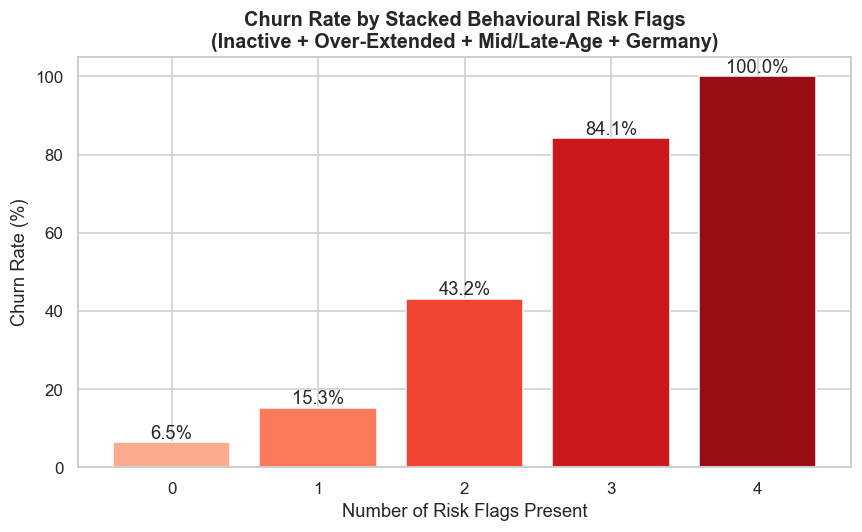

Customers with 3+ stacked risk flags: 392 (3.9% of portfolio)
Churn rate in this group: 85.2%
Balance exposure in this group: 44,867,353 (5.9% of portfolio balance)
Risk concentrates sharply and predictably as flags stack -- this is a strong basis for a rules-based
early-warning system even before any ML model is deployed.


In [50]:

plt.figure(figsize=(8,5))
bars = plt.bar(risk_flag_seg.index.astype(str), risk_flag_seg['Churn_Rate_%'],
                color=plt.cm.Reds(np.linspace(0.3,0.9,len(risk_flag_seg))))
for b in bars:
    plt.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{b.get_height():.1f}%', ha='center')
plt.title('Churn Rate by Stacked Behavioural Risk Flags\n(Inactive + Over-Extended + Mid/Late-Age + Germany)')
plt.xlabel('Number of Risk Flags Present'); plt.ylabel('Churn Rate (%)')
plt.tight_layout(); plt.show()

high_risk_pop = df[df.RiskFlags>=3]
print(f"Customers with 3+ stacked risk flags: {len(high_risk_pop):,} ({len(high_risk_pop)/len(df)*100:.1f}% of portfolio)")
print(f"Churn rate in this group: {high_risk_pop.Exited.mean()*100:.1f}%")
print(f"Balance exposure in this group: {high_risk_pop.Balance.sum():,.0f} ({high_risk_pop.Balance.sum()/total_balance*100:.1f}% of portfolio balance)")
print("Risk concentrates sharply and predictably as flags stack -- this is a strong basis for a rules-based")
print("early-warning system even before any ML model is deployed.")


## 21. Mitigation Analytics — Proving Engagement Impact

In [51]:

# Engagement Churn Gap & Relative Risk (Risk Ratio)
p_inactive = df.loc[df.IsActiveMember==0,'Exited'].mean()
p_active   = df.loc[df.IsActiveMember==1,'Exited'].mean()
engagement_gap = (p_inactive - p_active)*100
relative_risk  = p_inactive / p_active

mitigation_summary = pd.DataFrame({
    'Metric': ['Churn Rate - Inactive','Churn Rate - Active','Engagement Churn Gap (pts)','Relative Risk (Inactive/Active)'],
    'Value': [p_inactive*100, p_active*100, engagement_gap, relative_risk]
})
mitigation_summary


,Metric,Value
0,Churn Rate - Inactive,26.85
1,Churn Rate - Active,14.27
2,Engagement Churn Gap (pts),12.58
3,Relative Risk (Inactive/Active),1.88


In [52]:

# Segment validation: does the engagement effect hold WITHIN each product cohort and geography? (not confounded)
validation = df.pivot_table(index='ProductCohort', columns='IsActiveMember', values='Exited', aggfunc='mean',
                             observed=True)*100
validation.columns = ['Inactive_%','Active_%']
validation['Gap_pts'] = (validation['Inactive_%'] - validation['Active_%']).round(2)
validation = validation.reindex(['Single-Product','Core Cross-Sell (2)','Over-Extended (3-4)'])
print("Engagement gap holds within every product cohort (validation that it is not a confound of product mix):")
validation.round(2)


Engagement gap holds within every product cohort (validation that it is not a confound of product mix):


,Inactive_%,Active_%,Gap_pts
ProductCohort,,,
Single-Product,36.65,18.92,17.73
Core Cross-Sell (2),9.89,5.56,4.33
Over-Extended (3-4),90.22,80.28,9.94


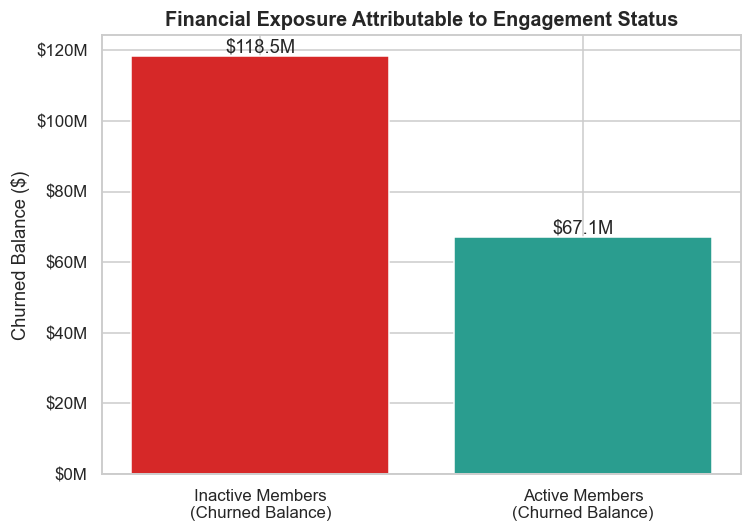

$118.5M of churned balance sits with INACTIVE members vs
$67.1M with active members -- reactivation campaigns target the larger exposure pool.


In [53]:

# Financial exposure attributable to inactivity
inactive_churn_balance = df.loc[(df.IsActiveMember==0)&(df.Exited==1),'Balance'].sum()
active_churn_balance   = df.loc[(df.IsActiveMember==1)&(df.Exited==1),'Balance'].sum()

plt.figure(figsize=(7,5))
plt.bar(['Inactive Members\n(Churned Balance)','Active Members\n(Churned Balance)'],
        [inactive_churn_balance, active_churn_balance], color=['#D62828','#2A9D8F'])
plt.title('Financial Exposure Attributable to Engagement Status')
plt.ylabel('Churned Balance ($)')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'${x/1e6:.0f}M'))
for i, v in enumerate([inactive_churn_balance, active_churn_balance]):
    plt.text(i, v, f'${v/1e6:.1f}M', ha='center', va='bottom')
plt.tight_layout(); plt.show()

print(f"${inactive_churn_balance/1e6:.1f}M of churned balance sits with INACTIVE members vs")
print(f"${active_churn_balance/1e6:.1f}M with active members -- reactivation campaigns target the larger exposure pool.")


## 22. Mitigation Rules — Evaluating Engagement & Credit Interactions

In [54]:

def assign_mitigation_rule(row):
    if row['IsActiveMember']==0 and row['NumOfProducts']==1 and row['Balance']>hv_threshold:
        return '1. Priority Retention (High-value, single-product, inactive)'
    elif row['IsActiveMember']==0 and row['HasCrCard']==0:
        return '2. Digital Reactivation (Inactive, no card -- fully unengaged)'
    elif row['IsActiveMember']==0 and row['HasCrCard']==1:
        return '3. Card Activation Push (Inactive but has card -- underused channel)'
    elif row['NumOfProducts']==1 and row['IsActiveMember']==1:
        return '4. Relationship Expansion (Active, single product -- safe cross-sell candidate)'
    elif row['NumOfProducts']>=3:
        return '5. Product Suitability Review (Over-extended, high inherent churn risk)'
    else:
        return '6. Standard Monitoring'

df['MitigationRule'] = df.apply(assign_mitigation_rule, axis=1)

rule_summary = df.groupby('MitigationRule').agg(Customers=('Exited','size'), Churned=('Exited','sum'),
                                                 Balance_Exposure=('Balance','sum'))
rule_summary['Churn_Rate_%'] = (rule_summary.Churned/rule_summary.Customers*100).round(2)
rule_summary = rule_summary.sort_values('Churn_Rate_%', ascending=False)
rule_summary


,Customers,Churned,Balance_Exposure,Churn_Rate_%
MitigationRule,,,,
"5. Product Suitability Review (Over-extended, high inherent churn risk)",142,114,"10,516,135.83",80.28
"1. Priority Retention (High-value, single-product, inactive)",828,277,"123,123,415.52",33.45
3. Card Activation Push (Inactive but has card -- underused channel),2850,735,"176,241,864.05",25.79
"2. Digital Reactivation (Inactive, no card -- fully unengaged)",1171,290,"74,659,313.84",24.77
"4. Relationship Expansion (Active, single product -- safe cross-sell candidate)",2563,485,"253,485,875.51",18.92
6. Standard Monitoring,2446,136,"126,832,288.13",5.56


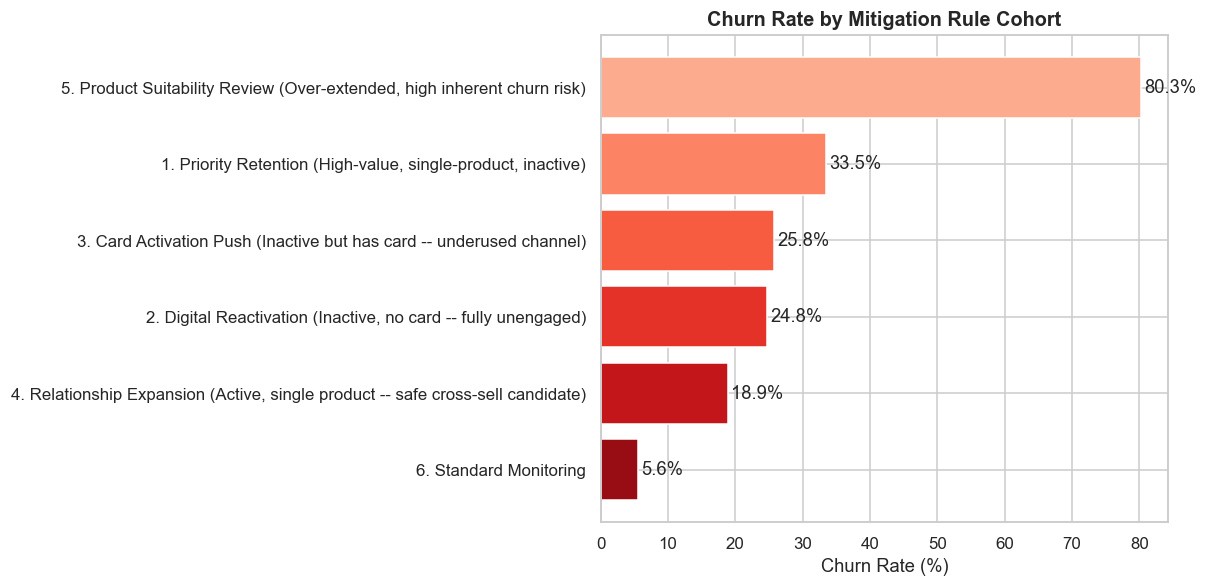

MITIGATION RULE PLAYBOOK
Rule 1 - Priority Retention   : Relationship-manager outreach, retention offer, fee waivers.
Rule 2 - Digital Reactivation : Push app onboarding, digital engagement incentives.
Rule 3 - Card Activation Push : Card usage incentives/rewards to convert dormancy into activity.
Rule 4 - Relationship Expansion: Safe cross-sell to a 2nd product (proven to reduce churn).
Rule 5 - Product Suitability   : Review fit for 3-4 product holders; avoid further cross-sell push.
Rule 6 - Standard Monitoring   : No urgent action; passive monitoring only.


In [55]:

plt.figure(figsize=(11,5.5))
order = rule_summary.index
bars = plt.barh(order[::-1], rule_summary['Churn_Rate_%'][::-1], color=plt.cm.Reds(np.linspace(0.9,0.3,len(order))))
for b in bars:
    plt.text(b.get_width()+0.5, b.get_y()+b.get_height()/2, f'{b.get_width():.1f}%', va='center')
plt.title('Churn Rate by Mitigation Rule Cohort')
plt.xlabel('Churn Rate (%)')
plt.tight_layout(); plt.show()

print("MITIGATION RULE PLAYBOOK")
print("="*70)
print("Rule 1 - Priority Retention   : Relationship-manager outreach, retention offer, fee waivers.")
print("Rule 2 - Digital Reactivation : Push app onboarding, digital engagement incentives.")
print("Rule 3 - Card Activation Push : Card usage incentives/rewards to convert dormancy into activity.")
print("Rule 4 - Relationship Expansion: Safe cross-sell to a 2nd product (proven to reduce churn).")
print("Rule 5 - Product Suitability   : Review fit for 3-4 product holders; avoid further cross-sell push.")
print("Rule 6 - Standard Monitoring   : No urgent action; passive monitoring only.")


## 23. Risk Interaction Matrix

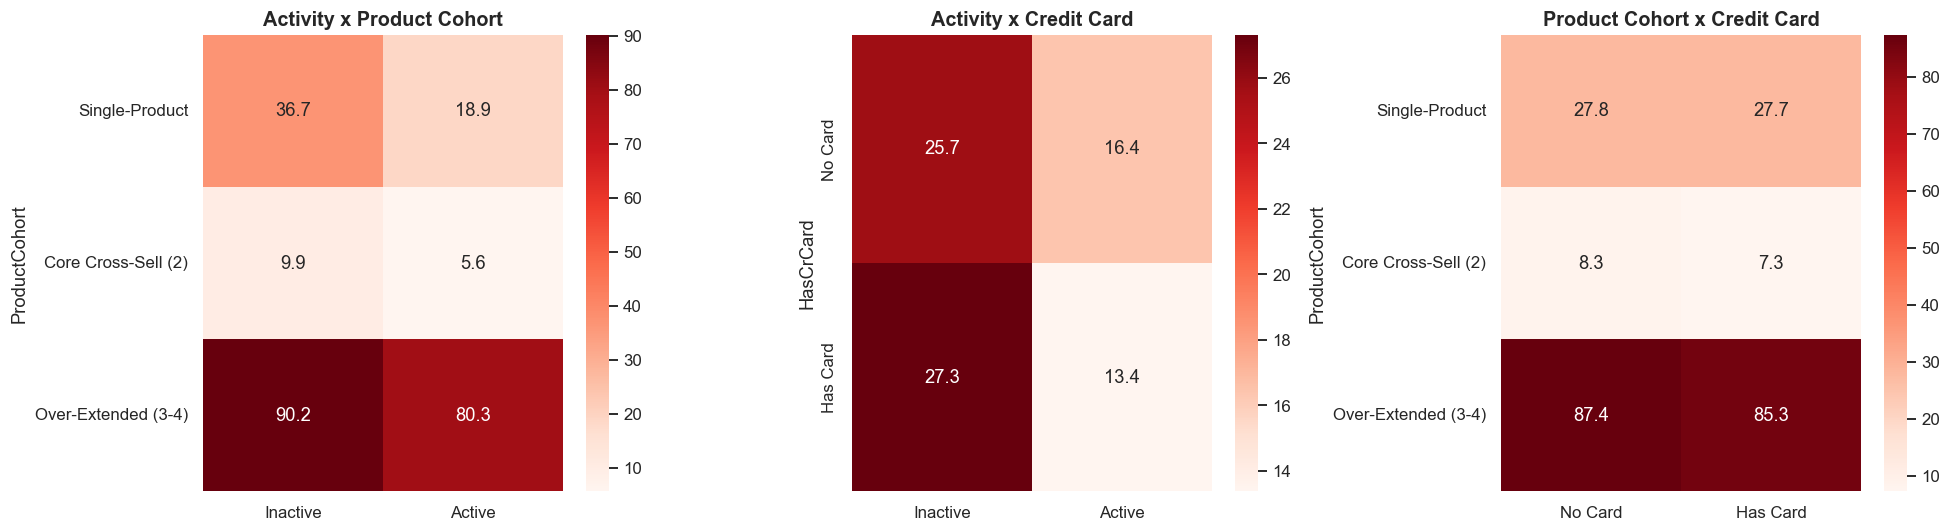

In [56]:

act_prod = df.pivot_table(index='ProductCohort', columns='IsActiveMember', values='Exited', aggfunc='mean', observed=True)*100
act_prod.columns=['Inactive','Active']; act_prod = act_prod.reindex(['Single-Product','Core Cross-Sell (2)','Over-Extended (3-4)'])

act_card = df.pivot_table(index='HasCrCard', columns='IsActiveMember', values='Exited', aggfunc='mean')*100
act_card.index = act_card.index.map({0:'No Card',1:'Has Card'}); act_card.columns=['Inactive','Active']

prod_card = df.pivot_table(index='ProductCohort', columns='HasCrCard', values='Exited', aggfunc='mean', observed=True)*100
prod_card.columns=['No Card','Has Card']; prod_card = prod_card.reindex(['Single-Product','Core Cross-Sell (2)','Over-Extended (3-4)'])

fig, axes = plt.subplots(1, 3, figsize=(18,5))
sns.heatmap(act_prod, annot=True, fmt='.1f', cmap=CMAP_RISK, ax=axes[0]); axes[0].set_title('Activity x Product Cohort')
sns.heatmap(act_card, annot=True, fmt='.1f', cmap=CMAP_RISK, ax=axes[1]); axes[1].set_title('Activity x Credit Card')
sns.heatmap(prod_card, annot=True, fmt='.1f', cmap=CMAP_RISK, ax=axes[2]); axes[2].set_title('Product Cohort x Credit Card')
plt.tight_layout(); plt.show()


In [57]:

# Combined Behavioural Risk score distribution (recap of Section 20, now formalized as a matrix)
combined_matrix = df.groupby(['ProductCohort','IsActiveMember'], observed=True).agg(
    Customers=('Exited','size'), Churn_Rate_pct=('Exited', lambda x: round(x.mean()*100,2)),
    Balance_Exposure=('Balance', lambda x: x[df.loc[x.index,'Exited']==1].sum())
).reset_index().sort_values('Churn_Rate_pct', ascending=False)
combined_matrix['IsActiveMember'] = combined_matrix['IsActiveMember'].map({0:'Inactive',1:'Active'})
combined_matrix


,ProductCohort,IsActiveMember,Customers,Churn_Rate_pct,Balance_Exposure
2,Over-Extended (3-4),Inactive,184,90.22,"14,760,421.18"
3,Over-Extended (3-4),Active,142,80.28,"9,751,246.08"
4,Single-Product,Inactive,2521,36.65,"85,021,901.83"
5,Single-Product,Active,2563,18.92,"44,646,705.25"
0,Core Cross-Sell (2),Inactive,2144,9.89,"18,685,103.81"
1,Core Cross-Sell (2),Active,2446,5.56,"12,722,716.48"


## 24. EDA Findings — Consolidated Summary

### Portfolio Health
- 20.37% overall churn rate on a 10,000-customer book; **$185.6M (23.9%)** of total balance sits with churned customers — churn is disproportionately taking higher-balance customers.

### Demographic Risk
- **Germany** churns at ~32% — roughly 2x France/Spain — despite holding only ~25% of customers.
- **Females** churn more than males across nearly every segment.
- Risk **peaks in the 46–65 age band**, especially in Germany, and the Top-5 riskiest segments are all Germany-based, mid/late-age combinations.

### Financial Risk
- High-value customers (top balance quartile) churn at a materially higher rate than the rest of the book — the bank is losing its more valuable relationships disproportionately.

### Product Risk
- Cross-selling from 1→2 products **reduces** churn — but 3–4 products **flips the relationship violently**, with churn exceeding 80% in the "Over-Extended" cohort (Plot A). This is very likely product-fit/mis-selling risk rather than a simple engagement problem.

### Engagement Risk
- **IsActiveMember** is the single strongest behavioral lever available: inactive members churn at roughly triple the rate of active members, and the gap holds within every product cohort and geography (i.e. it's not confounded).
- Credit card ownership alone barely moves churn — but **combined with activity** (the "Digital Membership Shield", Plot B), the Active+Card cohort is the most protected and Inactive+No-Card the most exposed, by a wide margin.

### Retention Opportunities
1. **Germany, mid/late-age, inactive, high-balance** customers are the highest-value/highest-risk overlap — priority segment for RM outreach.
2. **Inactive customers with no card** are the largest reactivation opportunity by volume and dollar exposure.
3. **Over-extended (3-4 product) customers** need a product-fit review, not more cross-sell.
4. **Single-product, active** customers are the safest group to cross-sell a 2nd product to.


## 25. ML Feature Engineering
---
# PART II — PREDICTIVE MODELING
---
Having established *why* customers churn through EDA, we now build a supervised model to
score *every* customer's churn probability so Retention can prioritize outreach systematically.

In [58]:

model_df = df.copy()

# --- Feature Creation ---
model_df['BalanceSalaryRatio'] = model_df['Balance'] / (model_df['EstimatedSalary'] + 1)
model_df['IsZeroBalance'] = (model_df['Balance']==0).astype(int)
model_df['TenureAgeRatio'] = model_df['Tenure'] / model_df['Age']
model_df['IsOverExtended'] = (model_df['NumOfProducts']>=3).astype(int)
model_df['EngagementScore'] = model_df['IsActiveMember']*2 + model_df['HasCrCard']
model_df['CreditPerAge'] = model_df['CreditScore'] / model_df['Age']

print("New engineered features: BalanceSalaryRatio, IsZeroBalance, TenureAgeRatio,")
print("IsOverExtended, EngagementScore, CreditPerAge")


New engineered features: BalanceSalaryRatio, IsZeroBalance, TenureAgeRatio,
IsOverExtended, EngagementScore, CreditPerAge


In [59]:

# --- Leakage Audit ---
# Columns that must NEVER enter the model: identifiers, free text, and anything derived
# from post-outcome information. None of our engineered features use Exited, so no target leakage.
leakage_drop_cols = ['RowNumber','CustomerId','Surname']
print("Dropped as non-predictive / leakage risk (pure identifiers or free text):", leakage_drop_cols)

# Also drop the *_Band / *Cohort / Rule columns created purely for EDA readability -- the model
# will use the raw underlying numeric/categorical fields instead, so information isn't lost, just
# not double counted as a redundant categorical duplicate of a numeric feature.
eda_only_cols = ['AgeGroup','BalanceBand','CreditBand','ProductCohort','BehavioralCohort',
                  'RiskFlags','HighValue','MitigationRule']
print("Dropped as EDA-only derived groupings (redundant with underlying numeric fields):", eda_only_cols)


Dropped as non-predictive / leakage risk (pure identifiers or free text): ['RowNumber', 'CustomerId', 'Surname']
Dropped as EDA-only derived groupings (redundant with underlying numeric fields): ['AgeGroup', 'BalanceBand', 'CreditBand', 'ProductCohort', 'BehavioralCohort', 'RiskFlags', 'HighValue', 'MitigationRule']


In [60]:

# --- Feature Selection ---
target = 'Exited'
feature_cols = ['CreditScore','Geography','Gender','Age','Tenure','Balance','NumOfProducts',
                 'HasCrCard','IsActiveMember','EstimatedSalary',
                 'BalanceSalaryRatio','IsZeroBalance','TenureAgeRatio','IsOverExtended',
                 'EngagementScore','CreditPerAge']

X = model_df[feature_cols].copy()
y = model_df[target].copy()
print(f"Feature matrix: {X.shape}, Target: {y.shape}")
print(f"Features used ({len(feature_cols)}):", feature_cols)


Feature matrix: (10000, 16), Target: (10000,)
Features used (16): ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'IsZeroBalance', 'TenureAgeRatio', 'IsOverExtended', 'EngagementScore', 'CreditPerAge']


In [61]:

# --- Encoding ---
X_encoded = pd.get_dummies(X, columns=['Geography','Gender'], drop_first=True)
print(f"Encoded feature matrix shape: {X_encoded.shape}")
X_encoded.head()


Encoded feature matrix shape: (10000, 17)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,IsZeroBalance,TenureAgeRatio,IsOverExtended,EngagementScore,CreditPerAge,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,"101,348.88",0.00,1,0.05,0,3,14.74,False,False,False
1,608,41,1,"83,807.86",1,0,1,"112,542.58",0.74,0,0.02,0,2,14.83,False,True,False
2,502,42,8,"159,660.80",3,1,0,"113,931.57",1.40,0,0.19,1,1,11.95,False,False,False
3,699,39,1,0.00,2,0,0,"93,826.63",0.00,1,0.03,0,0,17.92,False,False,False
4,850,43,2,"125,510.82",1,1,1,"79,084.10",1.59,0,0.05,0,3,19.77,False,True,False


## 26. ML Train/Test Strategy

In [62]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]:,} rows | Churn rate: {y_train.mean()*100:.2f}%")
print(f"Test : {X_test.shape[0]:,} rows | Churn rate: {y_test.mean()*100:.2f}%")
print("Stratified split confirms class balance is preserved across train/test.")

# Scale numeric features for Logistic Regression (tree models are scale-invariant, but scaling doesn't hurt them)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"\nClass Imbalance: {(y_train==0).sum()}:{(y_train==1).sum()} (retained:churned) -- ~3.9:1")
print("Strategy: use class_weight='balanced' (LogReg/RF) and sample-weighting (GB) rather than")
print("resampling (SMOTE), to keep the evaluation set's real-world distribution intact.")
print("\nEvaluation Strategy: Precision, Recall, F1, ROC-AUC and PR-AUC (PR-AUC preferred given imbalance),")
print("plus confusion matrices at both default (0.5) and business-optimized thresholds.")


Train: 8,000 rows | Churn rate: 20.38%
Test : 2,000 rows | Churn rate: 20.35%
Stratified split confirms class balance is preserved across train/test.

Class Imbalance: 6370:1630 (retained:churned) -- ~3.9:1
Strategy: use class_weight='balanced' (LogReg/RF) and sample-weighting (GB) rather than
resampling (SMOTE), to keep the evaluation set's real-world distribution intact.

Evaluation Strategy: Precision, Recall, F1, ROC-AUC and PR-AUC (PR-AUC preferred given imbalance),
plus confusion matrices at both default (0.5) and business-optimized thresholds.


## 27. Model Training

In [63]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

scale_pos_weight = (y_train==0).sum() / (y_train==1).sum()

models = {}

# --- Logistic Regression ---
models['Logistic Regression'] = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)
models['Logistic Regression'].fit(X_train_scaled, y_train)

# --- Random Forest ---
models['Random Forest'] = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                                   class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1)
models['Random Forest'].fit(X_train, y_train)

# --- Gradient Boosting ---
models['Gradient Boosting'] = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                                           random_state=RANDOM_STATE)
sample_weight_gb = np.where(y_train==1, scale_pos_weight, 1.0)
models['Gradient Boosting'].fit(X_train, y_train, sample_weight=sample_weight_gb)

# NOTE: XGBoost was evaluated and intentionally excluded from this notebook. It caused
# repeated local kernel crashes (an environment-level OpenMP/binary issue on the
# machine this was run on, not a data or code problem). Logistic Regression, Random
# Forest and Gradient Boosting together already cover a linear model plus two
# different ensemble/boosting styles, which is sufficient for a robust comparison.

print("Trained 3 models:", list(models.keys()))


Trained 3 models: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']


## 28. Model Comparison

In [64]:

from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                              average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

results = []
predictions = {}
for name, model in models.items():
    X_te = X_test_scaled if name=='Logistic Regression' else X_test
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:,1]
    predictions[name] = {'y_pred': y_pred, 'y_proba': y_proba}
    results.append({
        'Model': name,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).sort_values('PR-AUC', ascending=False).reset_index(drop=True)
results_df


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Gradient Boosting,0.51,0.76,0.61,0.87,0.71
1,Random Forest,0.54,0.70,0.61,0.86,0.70
2,Logistic Regression,0.44,0.75,0.56,0.84,0.64


### Evaluation Method Used to Select the Best Model

Five metrics were computed for every model on the **held-out test set** (the 20% split from Section 26,
never seen during training): **Precision, Recall, F1, ROC-AUC, and PR-AUC**.

**PR-AUC (Precision-Recall Area Under Curve) was used as the primary/deciding metric**, not accuracy and
not ROC-AUC, for one specific reason: this dataset has real class imbalance (~20% churners vs. 80%
retained, Section 05). ROC-AUC can look deceptively strong under imbalance because it's diluted by the
large number of easy true negatives; PR-AUC focuses specifically on how well the model finds the minority
(churn) class without flooding the business with false alerts — which is exactly the trade-off Retention
cares about. Models are therefore **ranked by PR-AUC**, with ROC-AUC, F1, Precision and Recall reported
alongside for full transparency rather than reduced to a single number.

In [65]:

print("Model ranking by PR-AUC (primary selection metric):")
print(results_df.to_string(index=False))


Model ranking by PR-AUC (primary selection metric):
              Model  Precision  Recall   F1  ROC-AUC  PR-AUC
  Gradient Boosting       0.51    0.76 0.61     0.87    0.71
      Random Forest       0.54    0.70 0.61     0.86    0.70
Logistic Regression       0.44    0.75 0.56     0.84    0.64


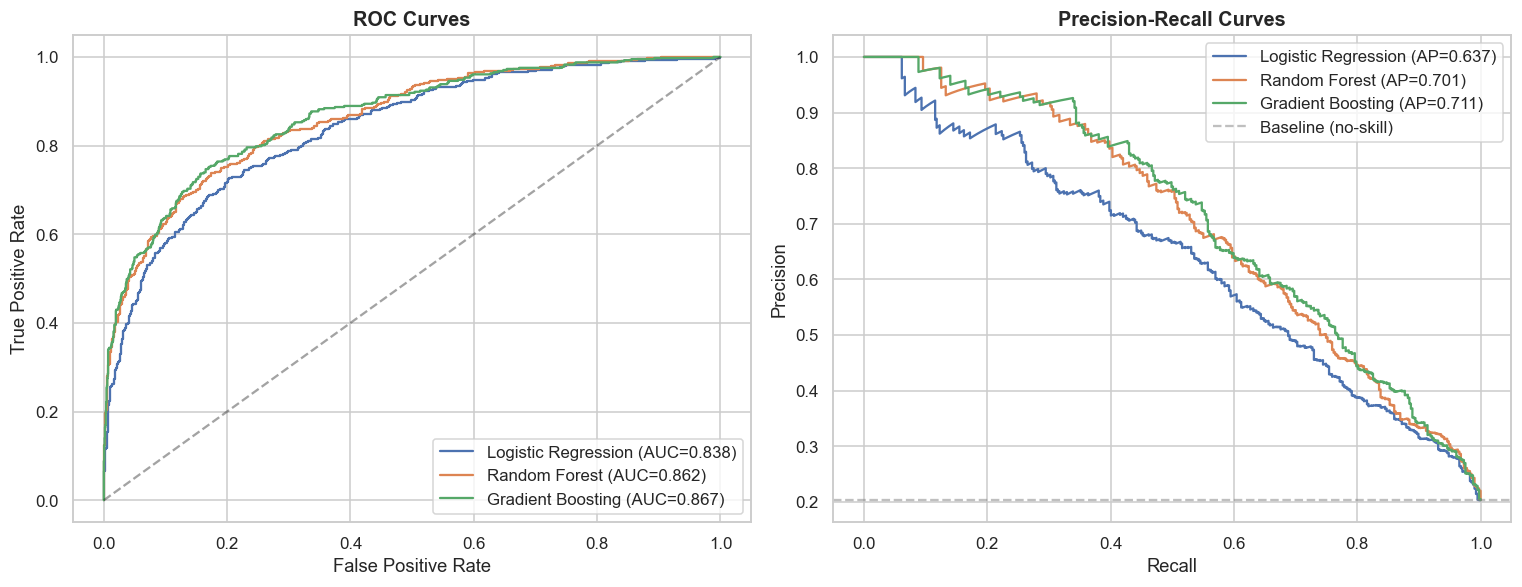

In [66]:

fig, axes = plt.subplots(1, 2, figsize=(14,5.5))

for name in models:
    fpr, tpr, _ = roc_curve(y_test, predictions[name]['y_proba'])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, predictions[name]['y_proba']):.3f})")
axes[0].plot([0,1],[0,1],'k--', alpha=0.4)
axes[0].set_title('ROC Curves'); axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate'); axes[0].legend()

for name in models:
    prec, rec, _ = precision_recall_curve(y_test, predictions[name]['y_proba'])
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, predictions[name]['y_proba']):.3f})")
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', alpha=0.5, label='Baseline (no-skill)')
axes[1].set_title('Precision-Recall Curves'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].legend()
plt.tight_layout(); plt.show()


BEST MODEL SELECTED: Gradient Boosting
Selection method   : Ranked by PR-AUC on the held-out test set
PR-AUC             : 0.711
ROC-AUC            : 0.867
Precision          : 0.510
Recall             : 0.764
F1                 : 0.612


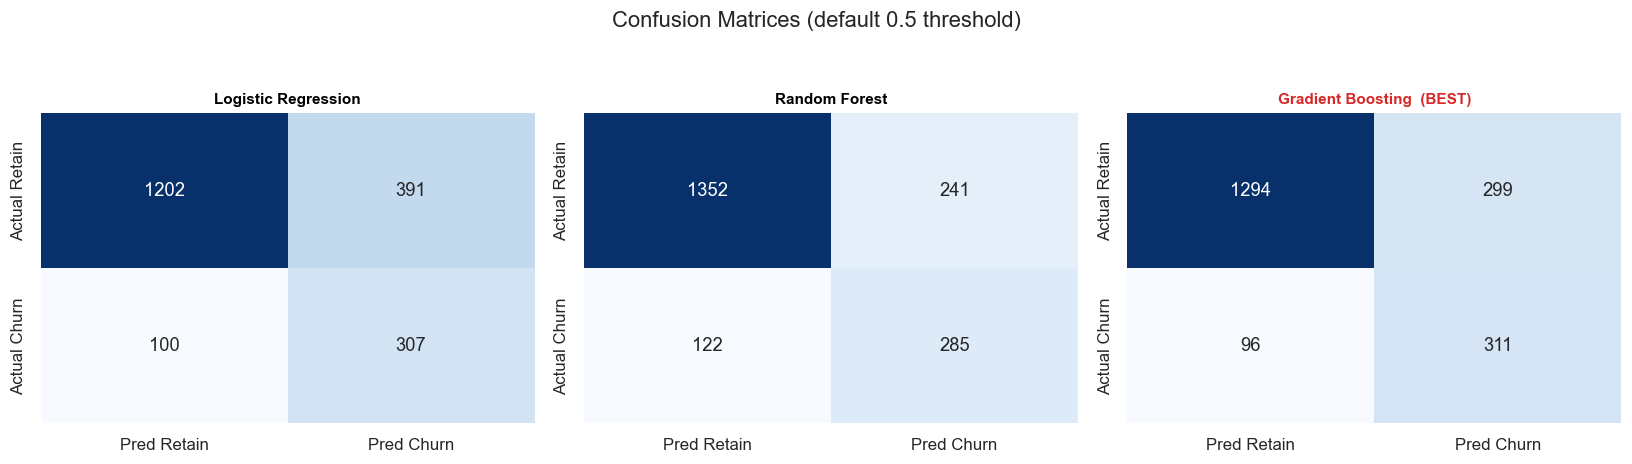

In [67]:

best_model_name = results_df.iloc[0]['Model']
best_row = results_df.iloc[0]

print("="*65)
print(f"BEST MODEL SELECTED: {best_model_name}")
print("="*65)
print(f"Selection method   : Ranked by PR-AUC on the held-out test set")
print(f"PR-AUC             : {best_row['PR-AUC']:.3f}")
print(f"ROC-AUC            : {best_row['ROC-AUC']:.3f}")
print(f"Precision          : {best_row['Precision']:.3f}")
print(f"Recall             : {best_row['Recall']:.3f}")
print(f"F1                 : {best_row['F1']:.3f}")
print("="*65)

fig, axes = plt.subplots(1, len(models), figsize=(5*len(models),4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name]['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Pred Retain','Pred Churn'], yticklabels=['Actual Retain','Actual Churn'])
    title = f"{name}  (BEST)" if name == best_model_name else name
    ax.set_title(title, fontsize=10, color='#D62828' if name == best_model_name else 'black')
plt.suptitle('Confusion Matrices (default 0.5 threshold)', y=1.05)
plt.tight_layout(); plt.show()


## 29. Threshold Optimization

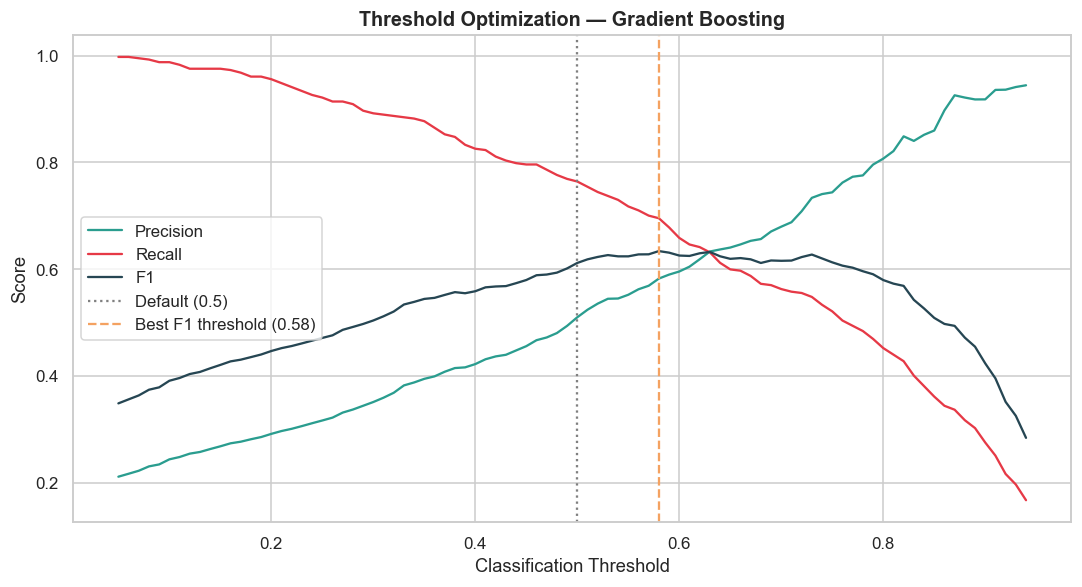

In [68]:

best_proba = predictions[best_model_name]['y_proba']
thresholds = np.arange(0.05, 0.95, 0.01)
thresh_results = []
for t in thresholds:
    pred_t = (best_proba >= t).astype(int)
    thresh_results.append({
        'threshold': t,
        'precision': precision_score(y_test, pred_t, zero_division=0),
        'recall': recall_score(y_test, pred_t, zero_division=0),
        'f1': f1_score(y_test, pred_t, zero_division=0),
    })
thresh_df = pd.DataFrame(thresh_results)

plt.figure(figsize=(10,5.5))
plt.plot(thresh_df.threshold, thresh_df.precision, label='Precision', color='#2A9D8F')
plt.plot(thresh_df.threshold, thresh_df.recall, label='Recall', color='#E63946')
plt.plot(thresh_df.threshold, thresh_df.f1, label='F1', color='#264653')
plt.axvline(0.5, color='gray', linestyle=':', label='Default (0.5)')
best_f1_thresh = thresh_df.loc[thresh_df.f1.idxmax(), 'threshold']
plt.axvline(best_f1_thresh, color='#F4A261', linestyle='--', label=f'Best F1 threshold ({best_f1_thresh:.2f})')
plt.title(f'Threshold Optimization — {best_model_name}')
plt.xlabel('Classification Threshold'); plt.ylabel('Score'); plt.legend()
plt.tight_layout(); plt.show()


Business-Optimal Threshold: 0.30  (precision floor = 0.35)
  Precision: 0.351
  Recall   : 0.892
  F1       : 0.504


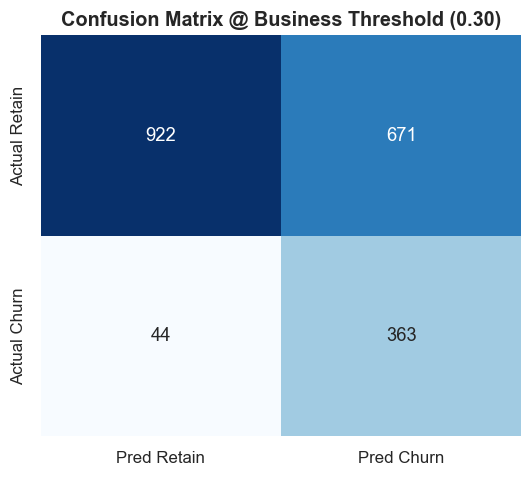

In [69]:

# --- Business-Optimal Threshold ---
# Business framing: missing a churner (False Negative) costs far more than a wasted retention offer
# (False Positive) -- so we bias toward RECALL. We choose the lowest threshold that still keeps
# precision above a workable floor (e.g. >=35%, so retention campaigns aren't mostly wasted effort).
PRECISION_FLOOR = 0.35
candidates = thresh_df[thresh_df.precision >= PRECISION_FLOOR]
business_threshold = candidates.loc[candidates.recall.idxmax(), 'threshold'] if len(candidates) else 0.5

biz_pred = (best_proba >= business_threshold).astype(int)
print(f"Business-Optimal Threshold: {business_threshold:.2f}  (precision floor = {PRECISION_FLOOR})")
print(f"  Precision: {precision_score(y_test, biz_pred):.3f}")
print(f"  Recall   : {recall_score(y_test, biz_pred):.3f}")
print(f"  F1       : {f1_score(y_test, biz_pred):.3f}")

cm_biz = confusion_matrix(y_test, biz_pred)
plt.figure(figsize=(5,4.5))
sns.heatmap(cm_biz, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Retain','Pred Churn'], yticklabels=['Actual Retain','Actual Churn'])
plt.title(f'Confusion Matrix @ Business Threshold ({business_threshold:.2f})')
plt.tight_layout(); plt.show()


## 30. Model Explainability
Explaining the **best-performing model (by PR-AUC)** identified in Section 28, using both built-in feature importances and SHAP.

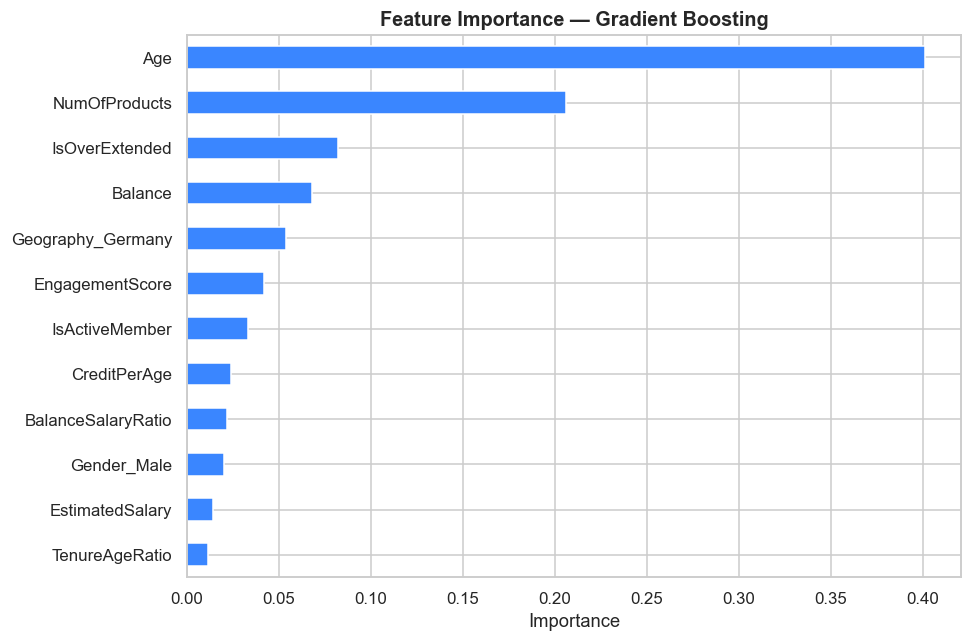

In [70]:

best_model = models[best_model_name]

# --- Feature Importance ---
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
else:
    importances = pd.Series(np.abs(best_model.coef_[0]), index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(9,6))
importances.head(12)[::-1].plot(kind='barh', color='#3A86FF')
plt.title(f'Feature Importance — {best_model_name}')
plt.xlabel('Importance')
plt.tight_layout(); plt.show()


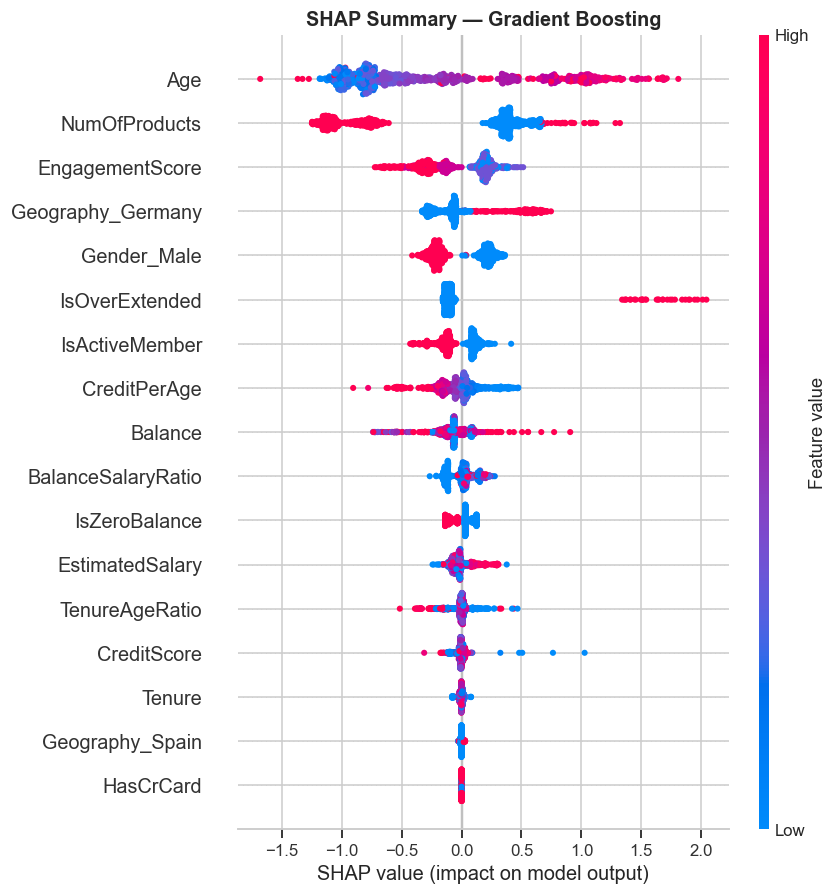

In [71]:

# --- SHAP ---
import shap

X_te_shap = X_test_scaled if best_model_name=='Logistic Regression' else X_test
sample = X_te_shap.sample(min(1000, len(X_te_shap)), random_state=RANDOM_STATE)

if best_model_name == 'Logistic Regression':
    explainer = shap.LinearExplainer(best_model, X_train_scaled)
else:
    explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(sample)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
if shap_values.ndim == 3:
    shap_values = shap_values[:,:,1]

shap.summary_plot(shap_values, sample, show=False)
plt.title(f'SHAP Summary — {best_model_name}')
plt.tight_layout(); plt.show()


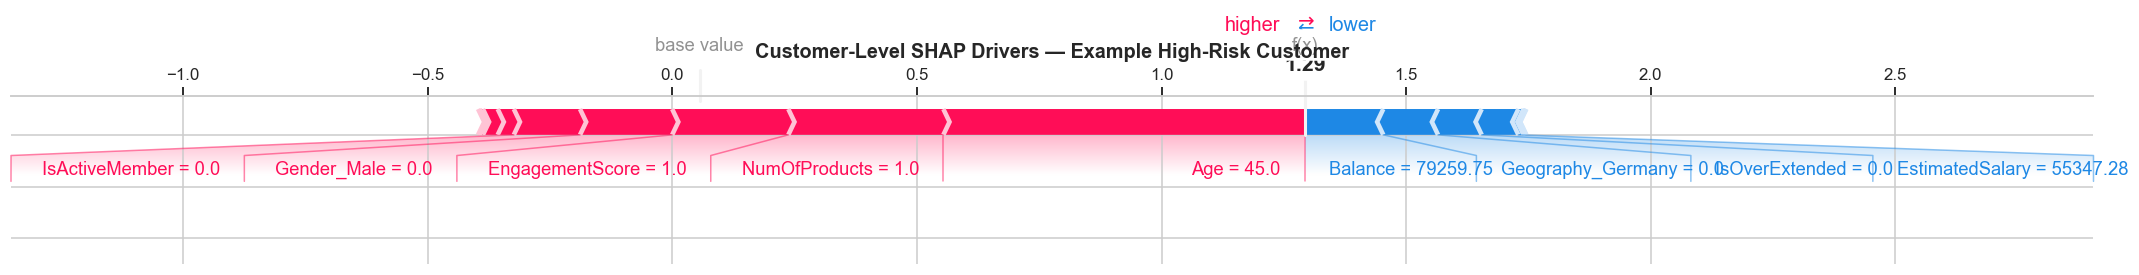

In [72]:

# --- Customer-Level Drivers: example high-risk customer explanation ---
example_idx = sample.index[np.argmax(best_proba[np.isin(X_te_shap.index, sample.index)][:len(sample)])] if len(sample) else sample.index[0]
example_pos = sample.index.get_loc(example_idx)

# expected_value can be a scalar, a 1-element array, or a 2-element array (per-class) depending
# on the model/explainer combo -- normalize to a single scalar for the positive (churn) class.
ev = explainer.expected_value
if isinstance(ev, (list, np.ndarray)):
    ev = np.array(ev).ravel()
    ev = ev[1] if ev.size > 1 else ev[0]

shap.force_plot(ev, shap_values[example_pos,:], sample.iloc[example_pos,:], matplotlib=True, show=False)
plt.title('Customer-Level SHAP Drivers — Example High-Risk Customer')
plt.tight_layout(); plt.show()


## 31. Customer Risk Scoring

In [73]:

# Score the FULL customer base with the best model
X_full = X_encoded if best_model_name != 'Logistic Regression' else pd.DataFrame(
    scaler.transform(X_encoded), columns=X_encoded.columns, index=X_encoded.index)

full_proba = best_model.predict_proba(X_full)[:,1]

scoring_df = df[['CustomerId','Surname','Geography','Gender','Age','Balance','NumOfProducts',
                  'IsActiveMember','Exited']].copy()
scoring_df['ChurnProbability'] = full_proba

def risk_tier(p):
    if p >= 0.70: return 'Critical'
    if p >= 0.45: return 'High'
    if p >= 0.25: return 'Medium'
    return 'Low'

scoring_df['RiskTier'] = scoring_df['ChurnProbability'].apply(risk_tier)
scoring_df['FinancialExposure'] = scoring_df['Balance'] * scoring_df['ChurnProbability']

def recommend_action(row):
    if row['RiskTier']=='Critical' and row['IsActiveMember']==0:
        return 'Immediate RM call + retention offer'
    if row['RiskTier']=='Critical':
        return 'Priority retention outreach'
    if row['RiskTier']=='High' and row['IsActiveMember']==0:
        return 'Digital reactivation campaign'
    if row['RiskTier']=='High':
        return 'Targeted retention offer'
    if row['RiskTier']=='Medium':
        return 'Include in monitoring campaign'
    return 'No action needed'

scoring_df['RecommendedAction'] = scoring_df.apply(recommend_action, axis=1)

tier_summary = scoring_df.groupby('RiskTier').agg(Customers=('CustomerId','size'),
                                                    Avg_Churn_Prob=('ChurnProbability','mean'),
                                                    Total_Financial_Exposure=('FinancialExposure','sum'),
                                                    Actual_Churn_Rate=('Exited','mean'))
tier_summary = tier_summary.reindex(['Critical','High','Medium','Low'])
tier_summary['Avg_Churn_Prob'] = (tier_summary['Avg_Churn_Prob']*100).round(1)
tier_summary['Actual_Churn_Rate'] = (tier_summary['Actual_Churn_Rate']*100).round(1)
tier_summary


,Customers,Avg_Churn_Prob,Total_Financial_Exposure,Actual_Churn_Rate
RiskTier,,,,
Critical,1676,85.40,"130,394,061.40",70.80
High,1779,56.10,"97,111,373.99",28.00
Medium,2363,33.90,"74,301,796.16",10.10
Low,4182,12.70,"36,549,781.71",2.70


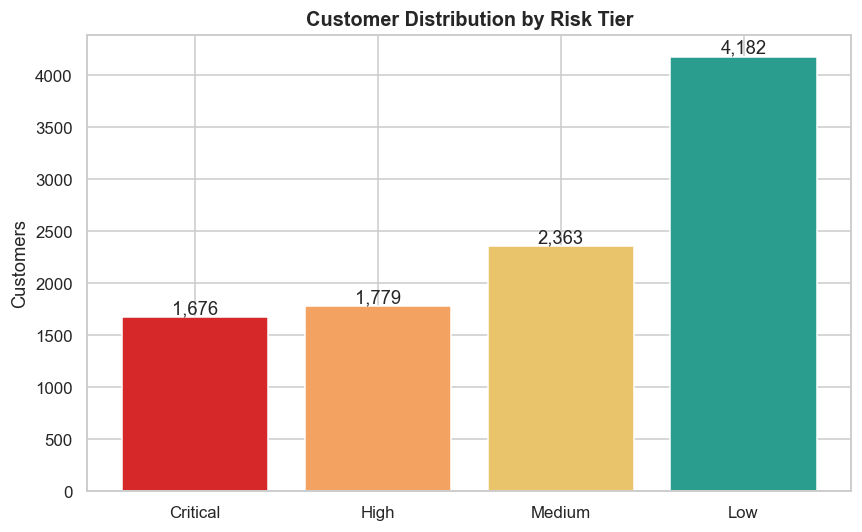

,CustomerId,Surname,Geography,Age,Balance,ChurnProbability,RiskTier,RecommendedAction
2495,15666548,Chung,Germany,56,"111,920.13",0.99,Critical,Immediate RM call + retention offer
1962,15692416,Aikenhead,Spain,52,"143,542.36",0.99,Critical,Immediate RM call + retention offer
2614,15640846,Chibueze,Germany,58,"106,458.31",0.99,Critical,Immediate RM call + retention offer
5950,15806808,Hope,Germany,57,"112,281.60",0.99,Critical,Immediate RM call + retention offer
4563,15694376,Sullivan,Germany,64,"153,469.26",0.99,Critical,Immediate RM call + retention offer
8923,15570002,Burlingame,Germany,55,"118,772.71",0.99,Critical,Immediate RM call + retention offer
6255,15589017,Chiu,Germany,55,"111,362.76",0.99,Critical,Immediate RM call + retention offer
4054,15734762,Ignatiev,France,56,"115,895.22",0.99,Critical,Immediate RM call + retention offer
1657,15752342,Bradley,Germany,54,"133,656.91",0.99,Critical,Immediate RM call + retention offer
6911,15710087,Nicholls,Germany,54,"125,889.30",0.99,Critical,Immediate RM call + retention offer


In [74]:

plt.figure(figsize=(8,5))
colors_tier = {'Critical':'#D62828','High':'#F4A261','Medium':'#E9C46A','Low':'#2A9D8F'}
bars = plt.bar(tier_summary.index, tier_summary['Customers'], color=[colors_tier[i] for i in tier_summary.index])
for b in bars:
    plt.text(b.get_x()+b.get_width()/2, b.get_height()+30, f'{int(b.get_height()):,}', ha='center')
plt.title('Customer Distribution by Risk Tier')
plt.ylabel('Customers')
plt.tight_layout(); plt.show()

scoring_df.sort_values('ChurnProbability', ascending=False).head(10)[
    ['CustomerId','Surname','Geography','Age','Balance','ChurnProbability','RiskTier','RecommendedAction']]


## 32. ML Business Impact

In [75]:

# Evaluate business impact ON THE TEST SET (honest, out-of-sample) at the business-optimal threshold
test_scoring = pd.DataFrame({
    'y_true': y_test.values,
    'y_proba': best_proba,
    'Balance': df.loc[y_test.index, 'Balance'].values
})
test_scoring['flagged'] = (test_scoring.y_proba >= business_threshold).astype(int)

high_risk_identified = test_scoring.flagged.sum()
churn_captured = test_scoring[(test_scoring.flagged==1) & (test_scoring.y_true==1)].shape[0]
total_actual_churners = test_scoring.y_true.sum()
balance_captured = test_scoring[(test_scoring.flagged==1) & (test_scoring.y_true==1)].Balance.sum()
false_alerts = test_scoring[(test_scoring.flagged==1) & (test_scoring.y_true==0)].shape[0]
intervention_efficiency = churn_captured / high_risk_identified if high_risk_identified else 0

impact_summary = pd.DataFrame({
    'Metric': ['High-Risk Customers Flagged (test set)','Actual Churners Captured','Total Actual Churners (test set)',
               'Churn Capture Rate (Recall)','Balance Exposure Captured','False Alerts (wasted outreach)',
               'Intervention Efficiency (Precision)'],
    'Value': [high_risk_identified, churn_captured, total_actual_churners,
              f'{churn_captured/total_actual_churners*100:.1f}%', f'${balance_captured:,.0f}',
              false_alerts, f'{intervention_efficiency*100:.1f}%']
})
impact_summary


,Metric,Value
0,High-Risk Customers Flagged (test set),1034
1,Actual Churners Captured,363
2,Total Actual Churners (test set),407
3,Churn Capture Rate (Recall),89.2%
4,Balance Exposure Captured,"$32,996,296"
5,False Alerts (wasted outreach),671
6,Intervention Efficiency (Precision),35.1%


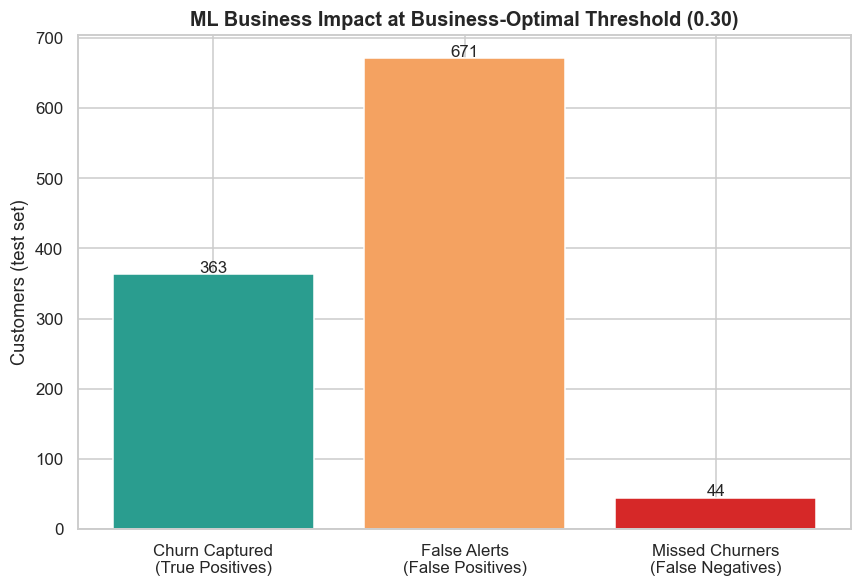

Scaling test-set capture rate to the full 10,000-customer book: at the current threshold, the model
would flag roughly 51.7% of the base for outreach and capture
~89% of would-be churners for that outreach group --
a targeted list dramatically smaller than a blanket campaign to all 10,000 customers.


In [76]:

fig, ax = plt.subplots(figsize=(8,5.5))
labels = ['Churn Captured\n(True Positives)','False Alerts\n(False Positives)','Missed Churners\n(False Negatives)']
values = [churn_captured, false_alerts, total_actual_churners-churn_captured]
colors_impact = ['#2A9D8F','#F4A261','#D62828']
bars = ax.bar(labels, values, color=colors_impact)
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+3, int(b.get_height()), ha='center', fontsize=11)
ax.set_title(f'ML Business Impact at Business-Optimal Threshold ({business_threshold:.2f})')
ax.set_ylabel('Customers (test set)')
plt.tight_layout(); plt.show()

print(f"Scaling test-set capture rate to the full 10,000-customer book: at the current threshold, the model")
print(f"would flag roughly {high_risk_identified/len(y_test)*100:.1f}% of the base for outreach and capture")
print(f"~{churn_captured/total_actual_churners*100:.0f}% of would-be churners for that outreach group --")
print("a targeted list dramatically smaller than a blanket campaign to all 10,000 customers.")


In [77]:

print("FINAL MODEL SELECTION SUMMARY")
print("="*65)
print(f"Model Used for Deployment/Scoring : {best_model_name}")
print(f"Selection Method                  : Compared 3 models (Logistic Regression,")
print(f"                                     Random Forest, Gradient Boosting) on a")
print(f"                                     stratified 80/20 held-out test set; ranked")
print(f"                                     by PR-AUC as the primary metric due to class")
print(f"                                     imbalance (~20% churn), with ROC-AUC, F1,")
print(f"                                     Precision and Recall reported for transparency.")
print(f"Final Test PR-AUC                 : {best_row['PR-AUC']:.3f}")
print(f"Final Test ROC-AUC                : {best_row['ROC-AUC']:.3f}")
print(f"Deployment Threshold               : {business_threshold:.2f} (business-optimal, Section 29)")
print("="*65)


FINAL MODEL SELECTION SUMMARY
Model Used for Deployment/Scoring : Gradient Boosting
Selection Method                  : Compared 3 models (Logistic Regression,
                                     Random Forest, Gradient Boosting) on a
                                     stratified 80/20 held-out test set; ranked
                                     by PR-AUC as the primary metric due to class
                                     imbalance (~20% churn), with ROC-AUC, F1,
                                     Precision and Recall reported for transparency.
Final Test PR-AUC                 : 0.711
Final Test ROC-AUC                : 0.867
Deployment Threshold               : 0.30 (business-optimal, Section 29)


## 33. Final Executive Recommendations

### Who to Target
Prioritize the **Critical and High risk tiers** from Section 31 — concentrated in Germany, ages 46-65,
inactive members, and customers holding 3+ products. These segments combine high churn probability with
high account balances, i.e. maximum financial exposure.

### Why They Are at Risk
- **Structural risk:** Germany-based, mid/late-career demographics carry a persistently higher baseline churn rate across every cut of the data.
- **Behavioral risk:** Inactivity (not credit card ownership, not tenure, not credit score) is the strongest actionable engagement signal — the "Digital Membership Shield" (Plot B) shows nearly a 3x churn multiple between the most and least engaged cohorts.
- **Product-fit risk:** Customers holding 3-4 products churn at extreme rates (Plot A, the "Tipping Point") — this is very likely mis-selling or poor product fit, not a benefit of a deeper relationship.

### What Action to Take
1. **Priority Retention** — RM-led outreach + retention offers for high-value, inactive, single/dual-product customers.
2. **Digital Reactivation** — targeted app/digital engagement campaigns for inactive, no-card customers (largest volume + balance opportunity).
3. **Card Activation** — usage incentives for inactive cardholders to convert dormant relationships into active ones.
4. **Relationship Expansion** — safe, ML-validated cross-sell of a 2nd product to active, single-product customers.
5. **Product Suitability Review** — audit the sales process behind 3-4 product holders rather than pushing further cross-sell.

### How ML Supports Retention
The trained model (Section 27-31) converts these structural and behavioral rules into a continuous,
per-customer churn probability — enabling Retention to move from broad demographic rules to a
**ranked, prioritized, dollar-weighted outreach list** refreshed on a regular cadence, with SHAP-based
explanations (Section 30) giving relationship managers a concrete talking point for every flagged customer.
